# Chest X-Ray Pneumonia Detection


**Contents**
1. Setup & configuration
2. Data loading
3. Exploratory Data Analysis
4. Train / validation / test split & class imbalance
5. Preprocessing pipeline (`tf.data` + augmentation)
6. Shared utilities (training, plotting, evaluation)
7. Model 1 — Baseline CNN + LSTM
8. Model 2 — DenseNet121 + LSTM
9. Model 3 — DenseNet121 + Multi-Head Cross-Attention
10. Final comparison & conclusion



## 1. Setup & configuration

In [19]:
!pip install -q kagglehub

In [20]:
!pip install -q mlflow

In [21]:
import os, time, random, hashlib, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image
from tqdm.auto import tqdm
from IPython.display import display, Markdown

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

from sklearn.model_selection import train_test_split
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, average_precision_score, matthews_corrcoef,
                             balanced_accuracy_score, confusion_matrix, classification_report,
                             roc_curve, precision_recall_curve)

warnings.filterwarnings("ignore")
SEED = 42
random.seed(SEED); np.random.seed(SEED); keras.utils.set_random_seed(SEED)

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 110, "axes.titleweight": "bold", "axes.titlesize": 12})

In [22]:
# ---------------- Global configuration ----------------
IMG_SIZE        = (224, 224)
INPUT_SHAPE     = (*IMG_SIZE, 3)
BATCH_SIZE      = 32
CLASS_NAMES     = ["NORMAL", "PNEUMONIA"]
LABEL_COLORS    = {"NORMAL": "#4C9F70", "PNEUMONIA": "#D1495B"}

# Training budgets (early stopping will usually stop sooner)
EPOCHS_BASELINE = 25     # CNN+LSTM trained from scratch
EPOCHS_HEAD     = 8      # transfer learning phase 1: frozen backbone
EPOCHS_FINETUNE = 12     # transfer learning phase 2: unfreeze last DenseNet block

# Names / colours used consistently in every plot
M1, M2, M3 = "Baseline CNN + LSTM", "DenseNet121 + LSTM", "DenseNet121 + Cross-Attention"
MODEL_COLORS = {M1: "#E07A5F", M2: "#3D85C6", M3: "#2A9D8F"}

os.makedirs("saved_models", exist_ok=True)
gpus = tf.config.list_physical_devices("GPU")
print(f"TensorFlow {tf.__version__} | Keras {keras.__version__} | GPUs: {[g.name for g in gpus] or 'NONE (training will be slow!)'}")

TensorFlow 2.20.0 | Keras 3.13.2 | GPUs: ['/physical_device:GPU:0', '/physical_device:GPU:1']


## 2. Data loading


In [23]:
import kagglehub
path = kagglehub.dataset_download("paultimothymooney/chest-xray-pneumonia")
print("Dataset path:", path)

# Locate the folder that contains train/ val/ test/ (the archive is sometimes nested)
base_dir = None
for root, dirs, _ in os.walk(path):
    if "__MACOSX" in root:
        continue
    if os.path.isdir(os.path.join(root, "train", "NORMAL")) and os.path.isdir(os.path.join(root, "test", "NORMAL")):
        base_dir = root
        break
assert base_dir is not None, "Could not find train/test folders"
print("Base dir:", base_dir)

Dataset path: /kaggle/input/datasets/paultimothymooney/chest-xray-pneumonia
Base dir: /kaggle/input/datasets/paultimothymooney/chest-xray-pneumonia/chest_xray


In [24]:
rows = []
for split in ["train", "val", "test"]:
    for label in CLASS_NAMES:
        class_dir = os.path.join(base_dir, split, label)
        if not os.path.isdir(class_dir):
            continue
        for fname in os.listdir(class_dir):
            if fname.lower().endswith((".png", ".jpg", ".jpeg")):
                rows.append({"image_path": os.path.join(class_dir, fname), "file_name": fname,
                             "label": label, "target": CLASS_NAMES.index(label), "split": split})

df = pd.DataFrame(rows)
print(f"Total images: {len(df):,}")
display(df.head())
df.info()
print("Missing values per column:\n", df.isnull().sum().to_string())

Total images: 5,856


,image_path,file_name,label,target,split
0,/kaggle/input/datasets/paultimothymooney/chest...,NORMAL2-IM-0771-0001.jpeg,NORMAL,0,train
1,/kaggle/input/datasets/paultimothymooney/chest...,NORMAL2-IM-1294-0001-0002.jpeg,NORMAL,0,train
2,/kaggle/input/datasets/paultimothymooney/chest...,IM-0675-0001.jpeg,NORMAL,0,train
3,/kaggle/input/datasets/paultimothymooney/chest...,NORMAL2-IM-1169-0001.jpeg,NORMAL,0,train
4,/kaggle/input/datasets/paultimothymooney/chest...,IM-0421-0001.jpeg,NORMAL,0,train


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5856 entries, 0 to 5855
Data columns (total 5 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   image_path  5856 non-null   object
 1   file_name   5856 non-null   object
 2   label       5856 non-null   object
 3   target      5856 non-null   int64 
 4   split       5856 non-null   object
dtypes: int64(1), object(4)
memory usage: 228.9+ KB
Missing values per column:
 image_path    0
file_name     0
label         0
target        0
split         0


### 2.1 Duplicate & data-leakage check


In [25]:
def md5_of(path, chunk=1 << 20):
    h = hashlib.md5()
    with open(path, "rb") as f:
        while block := f.read(chunk):
            h.update(block)
    return h.hexdigest()

df["md5"] = [md5_of(p) for p in tqdm(df["image_path"], desc="Hashing images")]

dup_groups = df.groupby("md5").filter(lambda g: len(g) > 1)
cross_split = df.groupby("md5")["split"].nunique()
print(f"Exact duplicate files   : {len(dup_groups)} images in {dup_groups['md5'].nunique()} groups")
print(f"Duplicates across splits: {(cross_split > 1).sum()} groups")
df = df.drop(columns="md5")

Hashing images:   0%|          | 0/5856 [00:00<?, ?it/s]

Exact duplicate files   : 62 images in 30 groups
Duplicates across splits: 0 groups


## 3. Exploratory Data Analysis
### 3.1 Class distribution

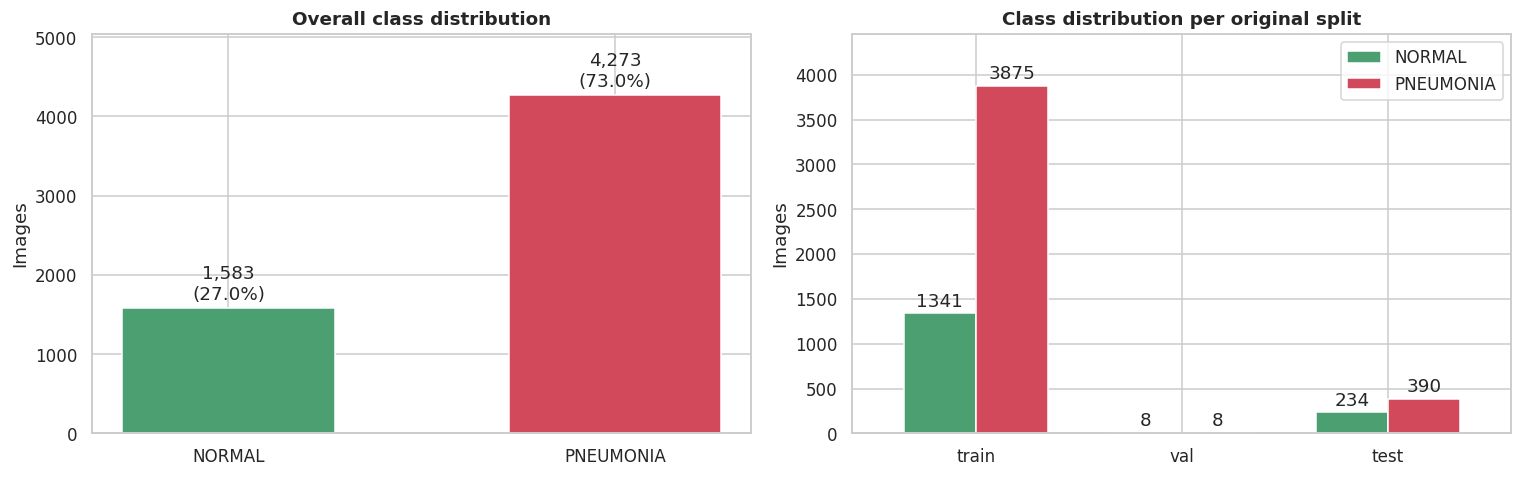

Imbalance ratio (PNEUMONIA : NORMAL) = 2.70 : 1


label,NORMAL,PNEUMONIA
split,,
train,1341,3875
val,8,8
test,234,390


In [26]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

# Overall
counts = df["label"].value_counts().reindex(CLASS_NAMES)
bars = axes[0].bar(counts.index, counts.values, color=[LABEL_COLORS[c] for c in counts.index], width=0.55)
axes[0].bar_label(bars, labels=[f"{v:,}\n({v/counts.sum():.1%})" for v in counts.values], padding=3)
axes[0].set_title("Overall class distribution"); axes[0].set_ylabel("Images")
axes[0].set_ylim(0, counts.max() * 1.18)

# Per original split
ct = pd.crosstab(df["split"], df["label"]).reindex(["train", "val", "test"])[CLASS_NAMES]
ct.plot(kind="bar", ax=axes[1], color=[LABEL_COLORS[c] for c in CLASS_NAMES], rot=0, width=0.7)
for cont in axes[1].containers:
    axes[1].bar_label(cont, padding=2)
axes[1].set_title("Class distribution per original split"); axes[1].set_xlabel(""); axes[1].set_ylabel("Images")
axes[1].set_ylim(0, ct.values.max() * 1.15); axes[1].legend(title="")
plt.tight_layout(); plt.show()

print(f"Imbalance ratio (PNEUMONIA : NORMAL) = {counts['PNEUMONIA'] / counts['NORMAL']:.2f} : 1")
display(ct)

### 3.2 Sample images

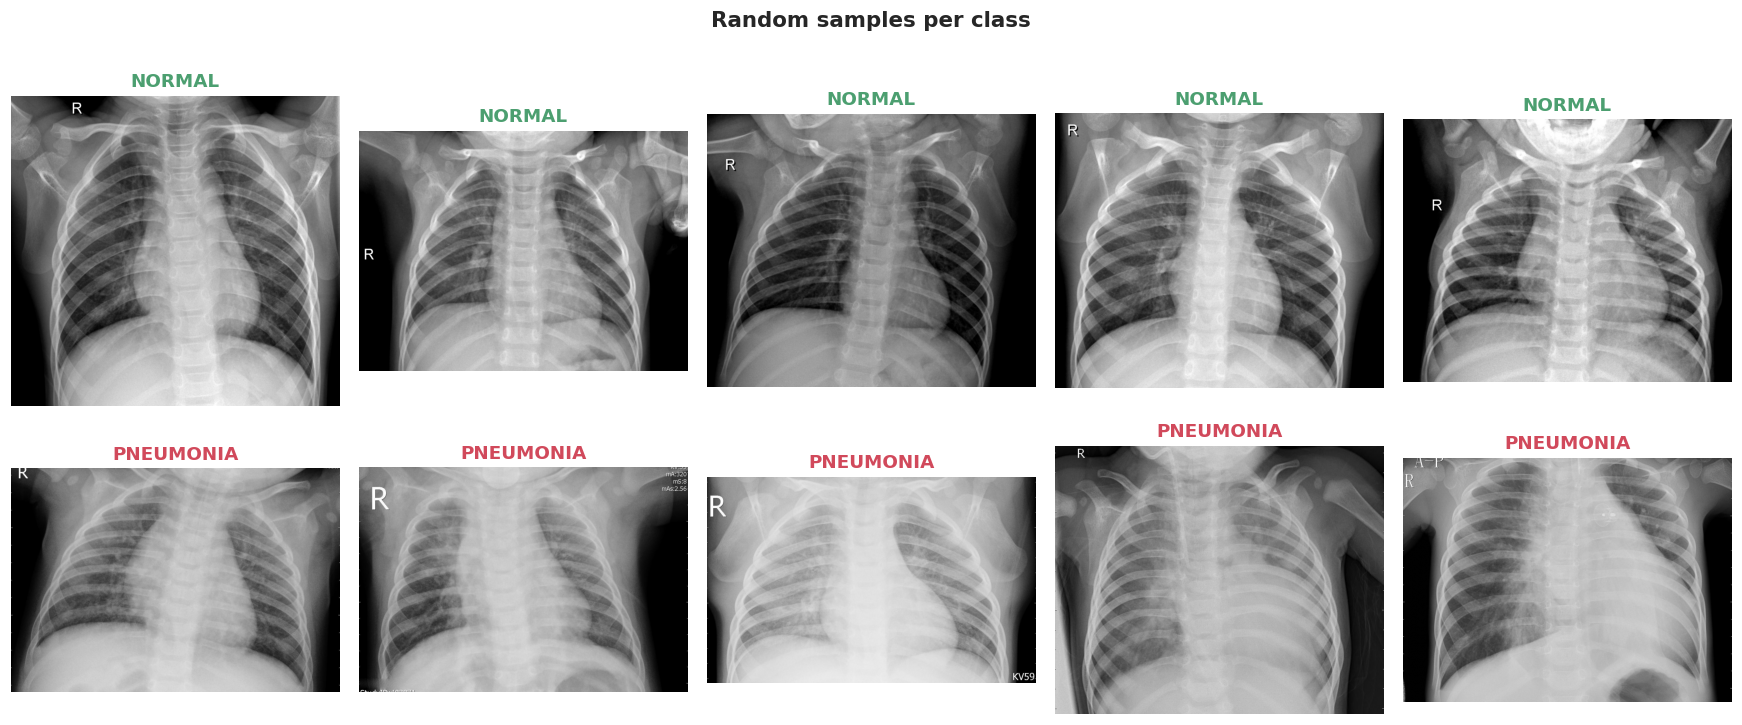

In [27]:
n_per_class = 5
fig, axes = plt.subplots(2, n_per_class, figsize=(3.2 * n_per_class, 7))
for r, cls in enumerate(CLASS_NAMES):
    sample = df[df["label"] == cls].sample(n_per_class, random_state=SEED)
    for c, (_, row) in enumerate(sample.iterrows()):
        axes[r, c].imshow(Image.open(row["image_path"]).convert("L"), cmap="gray")
        axes[r, c].set_title(cls, color=LABEL_COLORS[cls]); axes[r, c].axis("off")
plt.suptitle("Random samples per class", fontsize=14, fontweight="bold", y=1.0)
plt.tight_layout(); plt.show()

### 3.3 Image sizes & aspect ratios
The images come at very different resolutions, which is the main reason we must **resize** them to a fixed size.

Reading sizes:   0%|          | 0/5856 [00:00<?, ?it/s]

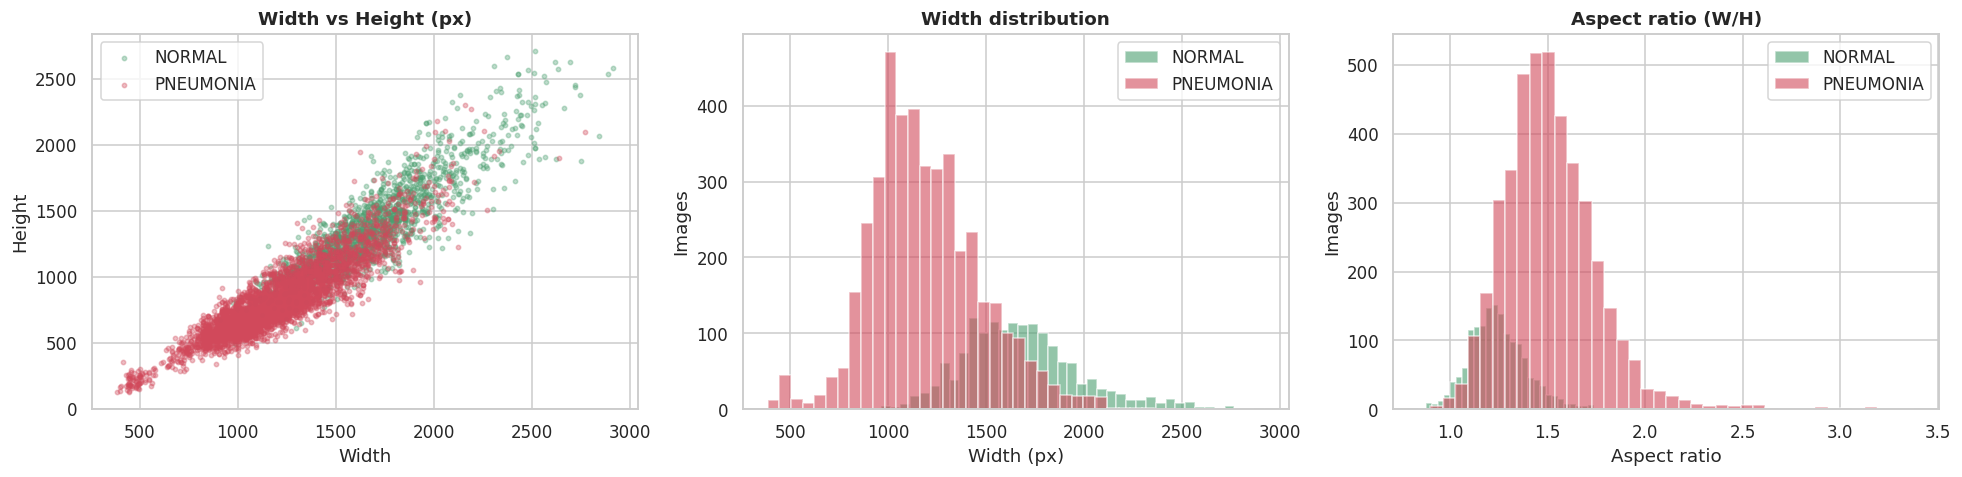

label          NORMAL  PNEUMONIA
width  count  1583.00    4273.00
       mean   1686.38    1195.07
       std     305.32     285.15
       min     912.00     384.00
       25%    1472.00    1000.00
       50%    1654.00    1160.00
       75%    1848.00    1360.00
       max    2916.00    2772.00
height count  1583.00    4273.00
       mean   1378.65     819.55
       std     343.02     270.86
       min     496.00     127.00
       25%    1140.00     640.00
       50%    1323.00     776.00
       75%    1554.00     960.00
       max    2713.00    2304.00
aspect count  1583.00    4273.00
       mean      1.25       1.51
       std       0.15       0.25
       min       0.88       0.84
       25%       1.15       1.36
       50%       1.23       1.49
       75%       1.34       1.65
       max       2.11       3.38

In [28]:
def get_size(p):
    with Image.open(p) as im:      # reads only the header → fast
        return im.size

sizes = [get_size(p) for p in tqdm(df["image_path"], desc="Reading sizes")]
df["width"], df["height"] = zip(*sizes)
df["aspect"] = df["width"] / df["height"]

fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))
for cls in CLASS_NAMES:
    s = df[df["label"] == cls]
    axes[0].scatter(s["width"], s["height"], s=8, alpha=0.35, label=cls, color=LABEL_COLORS[cls])
    axes[1].hist(s["width"], bins=40, alpha=0.6, label=cls, color=LABEL_COLORS[cls])
    axes[2].hist(s["aspect"], bins=40, alpha=0.6, label=cls, color=LABEL_COLORS[cls])
axes[0].set(title="Width vs Height (px)", xlabel="Width", ylabel="Height")
axes[1].set(title="Width distribution", xlabel="Width (px)", ylabel="Images")
axes[2].set(title="Aspect ratio (W/H)", xlabel="Aspect ratio", ylabel="Images")
for a in axes: a.legend()
plt.tight_layout(); plt.show()

display(df.groupby("label")[["width", "height", "aspect"]].describe().T.round(2))

### 3.4 Pixel-intensity analysis
.

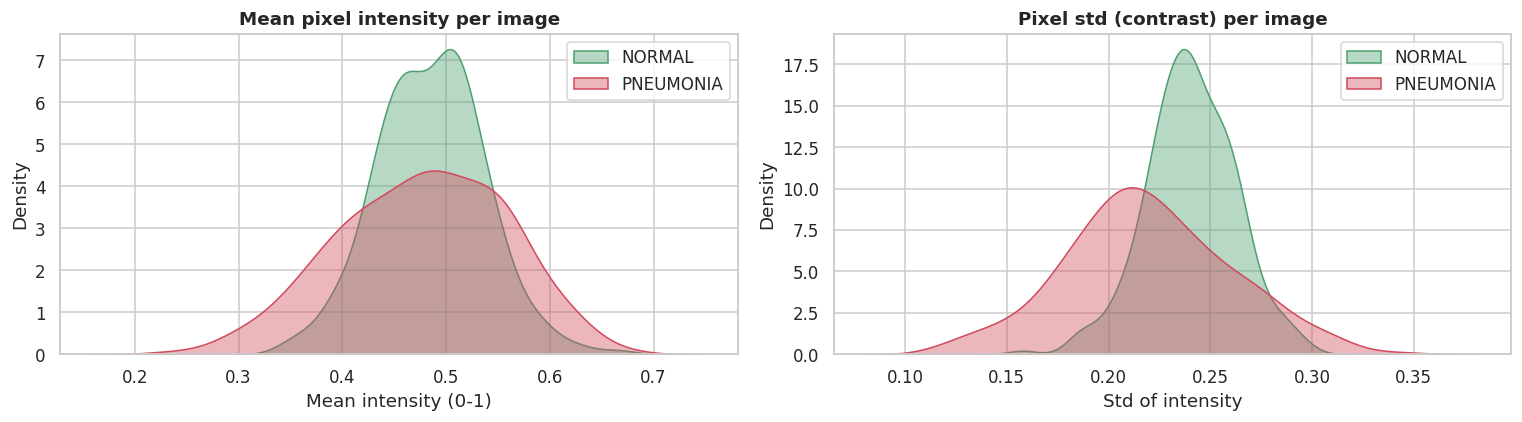

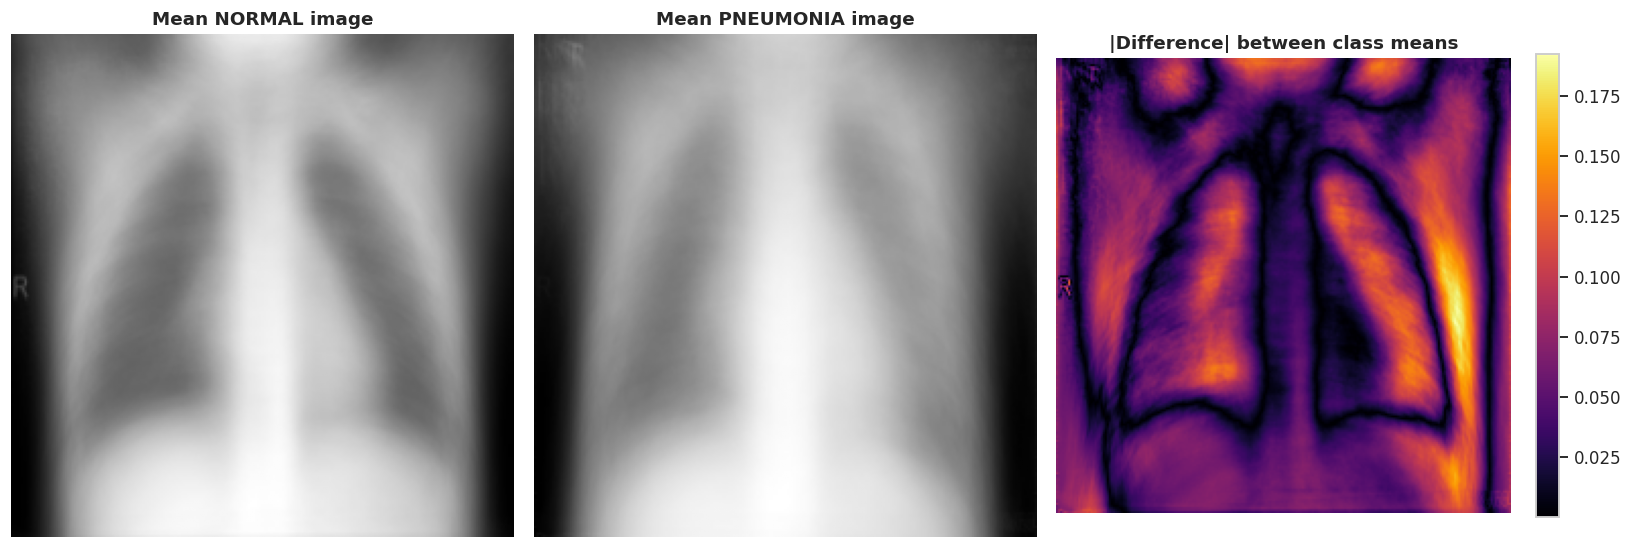

In [29]:
def load_gray(p, size=(224, 224)):
    return np.asarray(Image.open(p).convert("L").resize(size), dtype=np.float32) / 255.0

eda_sample = df.groupby("label", group_keys=False).sample(250, random_state=SEED)
imgs = {c: np.stack([load_gray(p) for p in eda_sample.loc[eda_sample.label == c, "image_path"]]) for c in CLASS_NAMES}

# --- brightness & contrast distributions
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
for c in CLASS_NAMES:
    sns.kdeplot(imgs[c].mean(axis=(1, 2)), ax=axes[0], fill=True, alpha=0.4, color=LABEL_COLORS[c], label=c)
    sns.kdeplot(imgs[c].std(axis=(1, 2)),  ax=axes[1], fill=True, alpha=0.4, color=LABEL_COLORS[c], label=c)
axes[0].set(title="Mean pixel intensity per image", xlabel="Mean intensity (0-1)")
axes[1].set(title="Pixel std (contrast) per image",  xlabel="Std of intensity")
for a in axes: a.legend()
plt.tight_layout(); plt.show()

# --- mean images
mean_img = {c: imgs[c].mean(axis=0) for c in CLASS_NAMES}
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
axes[0].imshow(mean_img["NORMAL"], cmap="gray");     axes[0].set_title("Mean NORMAL image")
axes[1].imshow(mean_img["PNEUMONIA"], cmap="gray");  axes[1].set_title("Mean PNEUMONIA image")
im = axes[2].imshow(np.abs(mean_img["PNEUMONIA"] - mean_img["NORMAL"]), cmap="inferno")
axes[2].set_title("|Difference| between class means"); plt.colorbar(im, ax=axes[2], fraction=0.046)
for a in axes: a.axis("off")
plt.tight_layout(); plt.show()

### 3.5 EDA takeaways → preprocessing decisions



## 4. Train / validation / test split & class weights

In [30]:
train_val_df = df[df["split"].isin(["train", "val"])].copy()
test_df      = df[df["split"] == "test"].copy().reset_index(drop=True)

train_df, val_df = train_test_split(train_val_df, test_size=0.15, stratify=train_val_df["target"], random_state=SEED)
train_df = train_df.reset_index(drop=True); val_df = val_df.reset_index(drop=True)

summary = pd.DataFrame({
    name: d["label"].value_counts().reindex(CLASS_NAMES).rename(name)
    for name, d in {"Train": train_df, "Validation": val_df, "Test": test_df}.items()
}).T
summary["Total"] = summary.sum(axis=1)
summary["% PNEUMONIA"] = (summary["PNEUMONIA"] / summary["Total"] * 100).round(1)
display(summary)

# Class weights (computed on TRAIN only)
classes = np.unique(train_df["target"])
cw = compute_class_weight("balanced", classes=classes, y=train_df["target"])
class_weight_dict = {int(c): float(w) for c, w in zip(classes, cw)}
print("Class weights:", {CLASS_NAMES[k]: round(v, 3) for k, v in class_weight_dict.items()})

label,NORMAL,PNEUMONIA,Total,% PNEUMONIA
Train,1147,3300,4447,74.2
Validation,202,583,785,74.3
Test,234,390,624,62.5


Class weights: {'NORMAL': 1.939, 'PNEUMONIA': 0.674}


## 5. Preprocessing pipeline



In [31]:
AUTOTUNE = tf.data.AUTOTUNE

def load_image(path, label):
    img = tf.io.read_file(path)
    img = tf.io.decode_image(img, channels=3, expand_animations=False)
    img.set_shape([None, None, 3])
    img = tf.image.resize(img, IMG_SIZE, method="bilinear")
    img = tf.cast(tf.round(img), tf.uint8)           # compact → cheap to cache in RAM
    return img, label

def make_dataset(frame, training=False):
    ds = tf.data.Dataset.from_tensor_slices((frame["image_path"].tolist(), frame["target"].values.astype("float32")))
    ds = ds.map(load_image, num_parallel_calls=AUTOTUNE).cache()
    if training:
        ds = ds.shuffle(2048, seed=SEED, reshuffle_each_iteration=True)
    return ds.batch(BATCH_SIZE).prefetch(AUTOTUNE)

train_ds = make_dataset(train_df, training=True)
val_ds   = make_dataset(val_df)
test_ds  = make_dataset(test_df)          # shuffle=False → order matches test_df
y_test   = test_df["target"].values

xb, yb = next(iter(train_ds))
print("Batch:", xb.shape, xb.dtype, "| labels:", yb.shape, "| pixel range:", int(tf.reduce_min(xb)), "-", int(tf.reduce_max(xb)))

I0000 00:00:1792868544.709635      49 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13756 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1792868544.717528      49 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13756 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5


Batch: (32, 224, 224, 3) <dtype: 'uint8'> | labels: (32,) | pixel range: 0 - 255


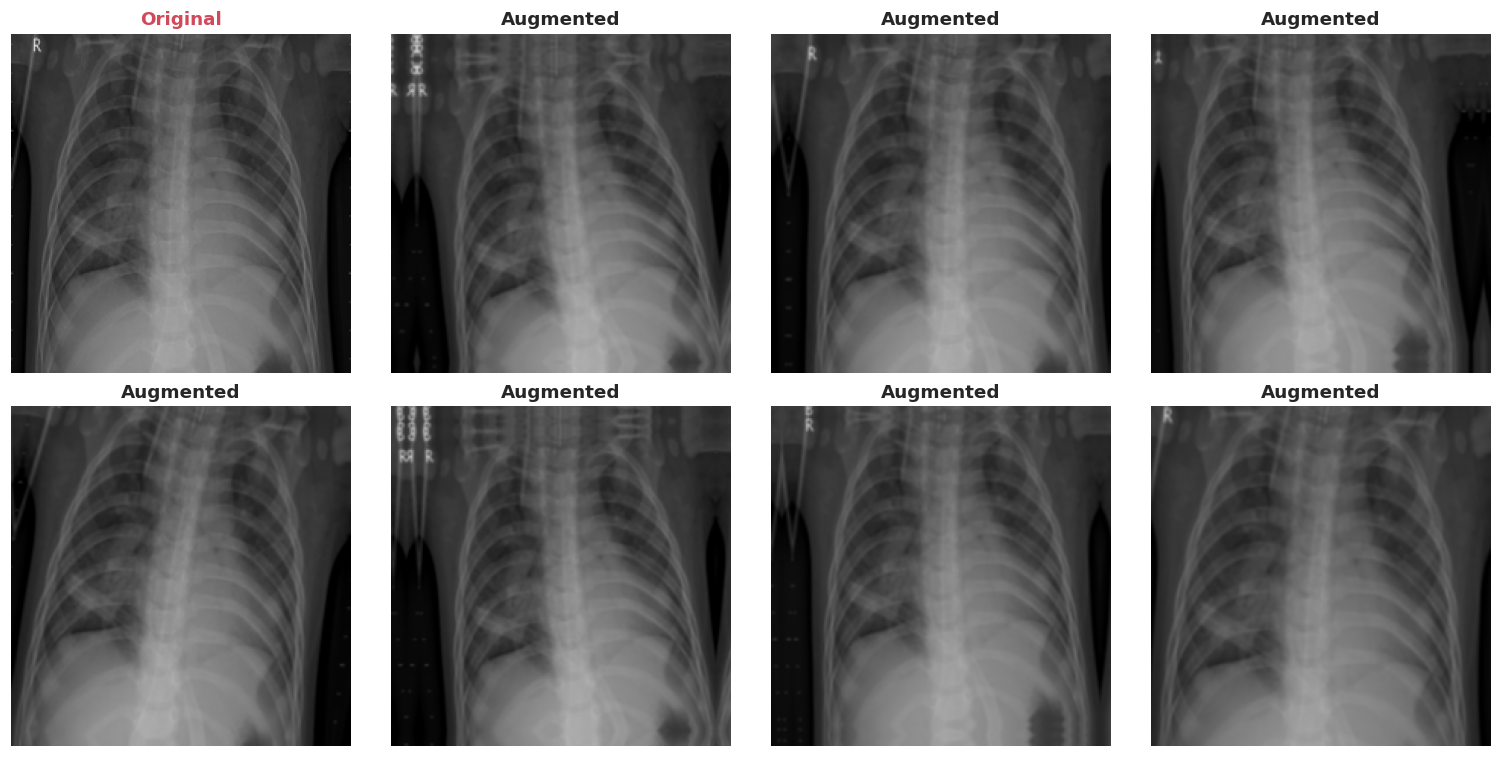

In [32]:
def make_augmentation():
    return keras.Sequential([
        layers.RandomRotation(0.03),                # ≈ ±11°
        layers.RandomTranslation(0.05, 0.05),
        layers.RandomZoom(0.10),
        layers.RandomContrast(0.15),
    ], name="augmentation")

def input_stem(inputs, imagenet_norm=False):
    """Rescale → augment (train only) → optional ImageNet normalisation."""
    x = layers.Rescaling(1.0 / 255)(inputs)
    x = make_augmentation()(x)
    if imagenet_norm:
        x = layers.Normalization(mean=[0.485, 0.456, 0.406],
                                 variance=[0.229 ** 2, 0.224 ** 2, 0.225 ** 2], name="imagenet_norm")(x)
    return x

# --- visualise the augmentation on one training image
demo_path = train_df[train_df["label"] == "PNEUMONIA"].iloc[0]["image_path"]
demo = np.asarray(Image.open(demo_path).convert("RGB").resize(IMG_SIZE), dtype=np.float32)[None] / 255.0
aug = make_augmentation()

fig, axes = plt.subplots(2, 4, figsize=(14, 7))
axes[0, 0].imshow(demo[0]); axes[0, 0].set_title("Original", color="#D1495B")
for a in axes.ravel()[1:]:
    a.imshow(np.clip(aug(demo, training=True)[0].numpy(), 0, 1)); a.set_title("Augmented")
for a in axes.ravel(): a.axis("off")
plt.tight_layout(); plt.show()

## 6. Shared utilities


In [33]:
def compile_model(model, lr):
    model.compile(
        optimizer=keras.optimizers.Adam(lr),
        loss="binary_crossentropy",
        metrics=["accuracy",
                 keras.metrics.AUC(name="auc"),
                 keras.metrics.Precision(name="precision"),
                 keras.metrics.Recall(name="recall")],
    )

def get_callbacks(patience):
    return [
        keras.callbacks.EarlyStopping(monitor="val_loss", patience=patience, restore_best_weights=True, verbose=1),
        keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.3, patience=2, min_lr=1e-7, verbose=1),
    ]

def merge_histories(*histories):
    out = {}
    for h in histories:
        for k, v in h.history.items():
            out.setdefault(k, []).extend(v)
    return out

def unfreeze_for_finetuning(backbone, prefix="conv5"):
    """Unfreeze only the last DenseNet dense-block (conv5_*). BatchNorm layers stay frozen."""
    backbone.trainable = True
    for layer in backbone.layers:
        layer.trainable = layer.name.startswith(prefix) and not isinstance(layer, layers.BatchNormalization)
    n_train = sum(int(np.prod(w.shape)) for l in backbone.layers if l.trainable for w in l.trainable_weights)
    print(f"Fine-tuning: {n_train:,} backbone parameters unfrozen (block '{prefix}')")

In [34]:
def plot_history(hist, title, finetune_start=None, color="#3D85C6"):
    metrics = [("loss", "Loss"), ("accuracy", "Accuracy"), ("auc", "AUC"), ("recall", "Recall")]
    epochs = np.arange(1, len(hist["loss"]) + 1)
    fig, axes = plt.subplots(1, 4, figsize=(20, 4))
    for ax, (k, name) in zip(axes, metrics):
        ax.plot(epochs, hist[k], "-o", ms=3, color=color, label="train")
        ax.plot(epochs, hist["val_" + k], "-o", ms=3, color="#444444", label="validation")
        if finetune_start:
            ax.axvline(finetune_start + 0.5, ls="--", color="gray", lw=1)
            ax.text(finetune_start + 0.6, ax.get_ylim()[0], " fine-tuning →", fontsize=8, color="gray", va="bottom")
        ax.set_title(name); ax.set_xlabel("Epoch"); ax.legend()
    fig.suptitle(f"Training curves — {title}", fontsize=14, fontweight="bold", y=1.03)
    plt.tight_layout(); plt.show()

results = {}   # name → dict with metrics, probabilities and history (filled after each model)

def evaluate_model(name, model, history, train_minutes, finetune_start=None, threshold=0.5):
    # --- predictions
    t0 = time.time()
    y_prob = model.predict(test_ds, verbose=0).ravel()
    infer_ms = (time.time() - t0) / len(y_prob) * 1000
    y_pred = (y_prob >= threshold).astype(int)
    val_prob = model.predict(val_ds, verbose=0).ravel()

    tn, fp, fn, tp = confusion_matrix(y_test, y_pred).ravel()
    m = {
        "Accuracy":     accuracy_score(y_test, y_pred),
        "Precision":    precision_score(y_test, y_pred, zero_division=0),
        "Recall":       recall_score(y_test, y_pred),
        "Specificity":  tn / (tn + fp),
        "F1":           f1_score(y_test, y_pred),
        "Macro F1":     f1_score(y_test, y_pred, average="macro"),
        "Balanced Acc": balanced_accuracy_score(y_test, y_pred),
        "MCC":          matthews_corrcoef(y_test, y_pred),
        "ROC-AUC":      roc_auc_score(y_test, y_prob),
        "PR-AUC":       average_precision_score(y_test, y_prob),
        "Val F1":       f1_score(val_df["target"].values, (val_prob >= threshold).astype(int)),
        "TP": int(tp), "TN": int(tn), "FP": int(fp), "FN": int(fn),
        "Params (M)":   model.count_params() / 1e6,
        "Train (min)":  train_minutes,
        "Infer (ms/img)": infer_ms,
    }

    # --- text report
    print(f"{'=' * 70}\n  TEST-SET EVALUATION — {name}  (threshold = {threshold})\n{'=' * 70}")
    print(classification_report(y_test, y_pred, target_names=CLASS_NAMES, digits=4))
    print(f"ROC-AUC {m['ROC-AUC']:.4f} | PR-AUC {m['PR-AUC']:.4f} | MCC {m['MCC']:.4f} | "
          f"Specificity {m['Specificity']:.4f} | FN (missed pneumonia) = {fn}")

    # --- plots: confusion matrix · ROC · PR · score distribution
    color = MODEL_COLORS[name]
    fig, axes = plt.subplots(1, 4, figsize=(21, 4.6))

    cm = confusion_matrix(y_test, y_pred)
    annot = np.array([[f"{cm[i, j]}\n({cm[i, j] / cm[i].sum():.1%})" for j in range(2)] for i in range(2)])
    sns.heatmap(cm, annot=annot, fmt="", cmap="Blues", cbar=False, ax=axes[0],
                xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES, annot_kws={"size": 13})
    axes[0].set(title="Confusion matrix", xlabel="Predicted", ylabel="Actual")

    fpr, tpr, _ = roc_curve(y_test, y_prob)
    axes[1].plot(fpr, tpr, color=color, lw=2.5, label=f"AUC = {m['ROC-AUC']:.3f}")
    axes[1].plot([0, 1], [0, 1], "k--", lw=1)
    axes[1].set(title="ROC curve", xlabel="False positive rate", ylabel="True positive rate"); axes[1].legend(loc="lower right")

    prec, rec, _ = precision_recall_curve(y_test, y_prob)
    axes[2].plot(rec, prec, color=color, lw=2.5, label=f"AP = {m['PR-AUC']:.3f}")
    axes[2].axhline(y_test.mean(), color="k", ls="--", lw=1, label="no-skill")
    axes[2].set(title="Precision–Recall curve", xlabel="Recall", ylabel="Precision", ylim=(0, 1.02)); axes[2].legend(loc="lower left")

    for i, cls in enumerate(CLASS_NAMES):
        axes[3].hist(y_prob[y_test == i], bins=30, alpha=0.65, color=LABEL_COLORS[cls], label=cls)
    axes[3].axvline(threshold, color="k", ls="--", lw=1)
    axes[3].set(title="Predicted-probability distribution", xlabel="P(PNEUMONIA)", ylabel="Images"); axes[3].legend()

    fig.suptitle(f"Test-set evaluation — {name}", fontsize=14, fontweight="bold", y=1.03)
    plt.tight_layout(); plt.show()

    results[name] = {"metrics": m, "y_prob": y_prob, "y_pred": y_pred, "history": history, "finetune_start": finetune_start}
    return m

### 6.1 MLflow tracking setup 
Each model will be logged as a Run inside the Experiment: the params + the metrics (for each epoch) and the test results + models of the 3 models on the MLflow UI. After that, we can compare the plots + weights.

In [35]:
import re, mlflow, mlflow.keras

mlflow.set_tracking_uri("sqlite:///mlflow.db")
mlflow.set_experiment("chest-xray-pneumonia")

def _clean(k):
    """MLflow metric names allow only letters, digits, _ - . space /  -> strip things like '(M)'."""
    return re.sub(r"[^\w\-. /]", "", k).strip().replace(" ", "_")

def log_to_mlflow(name, model, params, weights_path=None, log_full_model=True):
    """
    Log ONE trained model as an MLflow run. Call it right AFTER evaluate_model(...)
    because it reads results[name] (metrics, probabilities, history) from there.
    """
    r, m, hist = results[name], results[name]["metrics"], results[name]["history"]
    y_prob, y_pred = r["y_prob"], r["y_pred"]

    with mlflow.start_run(run_name=name) as run:
        mlflow.log_params({
            "model": name, "img_size": IMG_SIZE[0], "batch_size": BATCH_SIZE, "seed": SEED,
            "optimizer": "Adam", "loss": "binary_crossentropy",
            "n_train": len(train_df), "n_val": len(val_df), "n_test": len(test_df),
            "class_weight_normal": round(class_weight_dict[0], 3),
            "class_weight_pneumonia": round(class_weight_dict[1], 3),
            "total_params": model.count_params(),
            "finetune_start_epoch": r["finetune_start"] or "none",
            **params,
        })

        for ep in range(len(hist["loss"])):
            mlflow.log_metrics({_clean(k): float(v[ep]) for k, v in hist.items()}, step=ep + 1)

        mlflow.log_metrics({"test_" + _clean(k): float(v) for k, v in m.items()})

        fig, ax = plt.subplots(1, 3, figsize=(16, 4.5))
        cm = confusion_matrix(y_test, y_pred)
        sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax[0],
                    xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES)
        ax[0].set(title="Confusion matrix", xlabel="Predicted", ylabel="Actual")
        fpr, tpr, _ = roc_curve(y_test, y_prob)
        ax[1].plot(fpr, tpr, lw=2.5, label=f"AUC={m['ROC-AUC']:.3f}"); ax[1].plot([0, 1], [0, 1], "k--")
        ax[1].set(title="ROC", xlabel="FPR", ylabel="TPR"); ax[1].legend()
        prec, rec, _ = precision_recall_curve(y_test, y_prob)
        ax[2].plot(rec, prec, lw=2.5, label=f"AP={m['PR-AUC']:.3f}")
        ax[2].set(title="Precision-Recall", xlabel="Recall", ylabel="Precision"); ax[2].legend()
        plt.tight_layout(); mlflow.log_figure(fig, "plots/test_evaluation.png"); plt.close(fig)

        fig, ax = plt.subplots(1, 2, figsize=(11, 4))
        for k in ["loss", "auc"]:
            i = 0 if k == "loss" else 1
            ax[i].plot(hist[k], label="train"); ax[i].plot(hist["val_" + k], label="val")
            ax[i].set(title=k, xlabel="epoch"); ax[i].legend()
        plt.tight_layout(); mlflow.log_figure(fig, "plots/training_curves.png"); plt.close(fig)

        mlflow.log_text(classification_report(y_test, y_pred, target_names=CLASS_NAMES, digits=4),
                        "classification_report.txt")
        if weights_path and os.path.exists(weights_path):
            mlflow.log_artifact(weights_path, artifact_path="weights")
        if log_full_model:
            try:
                mlflow.keras.log_model(model, name="model")           # MLflow >= 3
            except TypeError:
                mlflow.keras.log_model(model, artifact_path="model")  # MLflow 2.x
            except Exception as e:
                print("Full-model logging skipped (weights are still saved):", e)

        print(f"Logged '{name}' -> run_id = {run.info.run_id}")
        return run.info.run_id

run_ids = {}

2026/10/24 19:02:44 INFO mlflow.store.db.utils: Creating initial MLflow database tables...
2026/10/24 19:02:44 INFO mlflow.store.db.utils: Updating database tables
2026/10/24 19:02:47 INFO mlflow.tracking.fluent: Experiment with name 'chest-xray-pneumonia' does not exist. Creating a new experiment.


## 7. Model 1 — Baseline CNN + LSTM



In [36]:
def build_baseline_cnn_lstm():
    inputs = keras.Input(INPUT_SHAPE, name="image")
    x = input_stem(inputs)
    for f in [32, 64, 128, 128]:
        for _ in range(2):
            x = layers.Conv2D(f, 3, padding="same", use_bias=False)(x)
            x = layers.BatchNormalization()(x)
            x = layers.ReLU()(x)
        x = layers.MaxPooling2D()(x)
        x = layers.Dropout(0.25)(x)
    x = layers.Reshape((-1, 128), name="to_sequence")(x)       # (196, 128)
    x = layers.LSTM(128, name="lstm")(x)
    x = layers.Dropout(0.4)(x)
    x = layers.Dense(64, activation="relu")(x)
    x = layers.Dropout(0.3)(x)
    outputs = layers.Dense(1, activation="sigmoid", name="pneumonia_prob")(x)
    return keras.Model(inputs, outputs, name="baseline_cnn_lstm")

keras.backend.clear_session()
model_1 = build_baseline_cnn_lstm()
model_1.summary()

Model: "baseline_cnn_lstm"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ image (InputLayer)              │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling (Rescaling)           │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ augmentation (Sequential)       │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 224, 224, 32)   │           864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 224, 224, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu (ReLU)                    │ (None, 224, 224, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 224, 224, 32)   │         9,216 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 224, 224, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_1 (ReLU)                  │ (None, 224, 224, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 112, 112, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 112, 112, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 112, 112, 64)   │        18,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 112, 112, 64)   │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_2 (ReLU)                  │ (None, 112, 112, 64)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 112, 112, 64)   │        36,864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 112, 112, 64)   │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_3 (ReLU)                  │ (None, 112, 112, 64)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 56, 56, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 56, 56, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 56, 56, 128)    │        73,728 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 56, 56, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_4 (ReLU)                  │ (None, 56, 56, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼─────────────

 Total params: 724,193 (2.76 MB)

 Trainable params: 722,785 (2.76 MB)

 Non-trainable params: 1,408 (5.50 KB)

In [37]:
compile_model(model_1, lr=1e-3)
t0 = time.time()
h1 = model_1.fit(train_ds, validation_data=val_ds, epochs=EPOCHS_BASELINE,
                 class_weight=class_weight_dict, callbacks=get_callbacks(patience=6), verbose=2)
time_1 = (time.time() - t0) / 60
hist_1 = merge_histories(h1)
model_1.save_weights("saved_models/baseline_cnn_lstm.weights.h5")
print(f"\nTraining time: {time_1:.1f} min")

Epoch 1/25


E0000 00:00:1792868573.350743      49 meta_optimizer.cc:967] layout failed: INVALID_ARGUMENT: Size of values 0 does not match size of permutation 4 @ fanin shape inStatefulPartitionedCall/baseline_cnn_lstm_1/dropout_1/stateless_dropout/SelectV2-2-TransposeNHWCToNCHW-LayoutOptimizer


139/139 - 71s - 513ms/step - accuracy: 0.6742 - auc: 0.7441 - loss: 0.6005 - precision: 0.8742 - recall: 0.6552 - val_accuracy: 0.2803 - val_auc: 0.7005 - val_loss: 1.4383 - val_precision: 1.0000 - val_recall: 0.0309 - learning_rate: 0.0010
Epoch 2/25
139/139 - 48s - 344ms/step - accuracy: 0.7668 - auc: 0.8532 - loss: 0.4711 - precision: 0.9344 - recall: 0.7376 - val_accuracy: 0.7427 - val_auc: 0.4983 - val_loss: 1.0078 - val_precision: 0.7427 - val_recall: 1.0000 - learning_rate: 0.0010
Epoch 3/25
139/139 - 47s - 340ms/step - accuracy: 0.6440 - auc: 0.7139 - loss: 0.6280 - precision: 0.8540 - recall: 0.6276 - val_accuracy: 0.7427 - val_auc: 0.6403 - val_loss: 0.6435 - val_precision: 0.7427 - val_recall: 1.0000 - learning_rate: 0.0010
Epoch 4/25
139/139 - 48s - 348ms/step - accuracy: 0.7846 - auc: 0.8850 - loss: 0.4187 - precision: 0.9439 - recall: 0.7545 - val_accuracy: 0.2650 - val_auc: 0.5315 - val_loss: 1.5294 - val_precision: 1.0000 - val_recall: 0.0103 - learning_rate: 0.0010
Epo

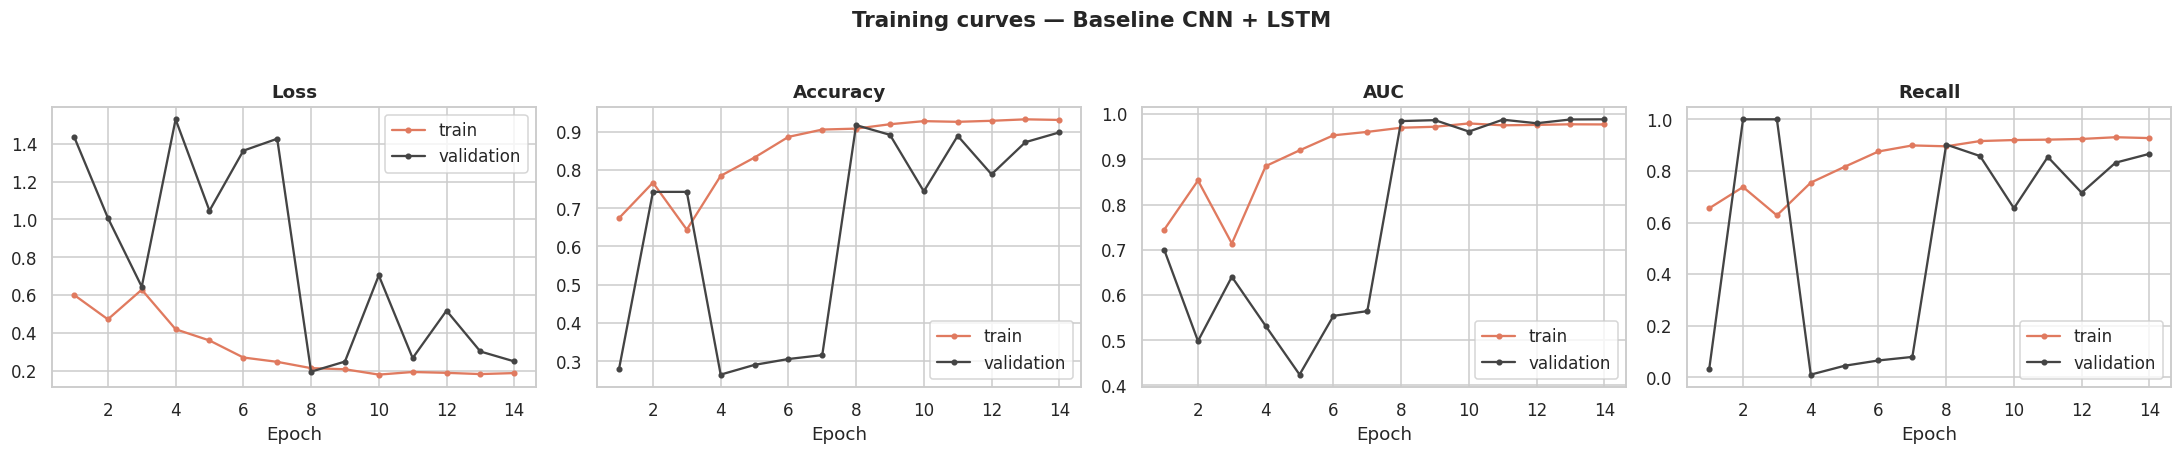

  TEST-SET EVALUATION — Baseline CNN + LSTM  (threshold = 0.5)
              precision    recall  f1-score   support

      NORMAL     0.8882    0.6453    0.7475       234
   PNEUMONIA     0.8172    0.9513    0.8791       390

    accuracy                         0.8365       624
   macro avg     0.8527    0.7983    0.8133       624
weighted avg     0.8438    0.8365    0.8298       624

ROC-AUC 0.9198 | PR-AUC 0.9424 | MCC 0.6487 | Specificity 0.6453 | FN (missed pneumonia) = 19


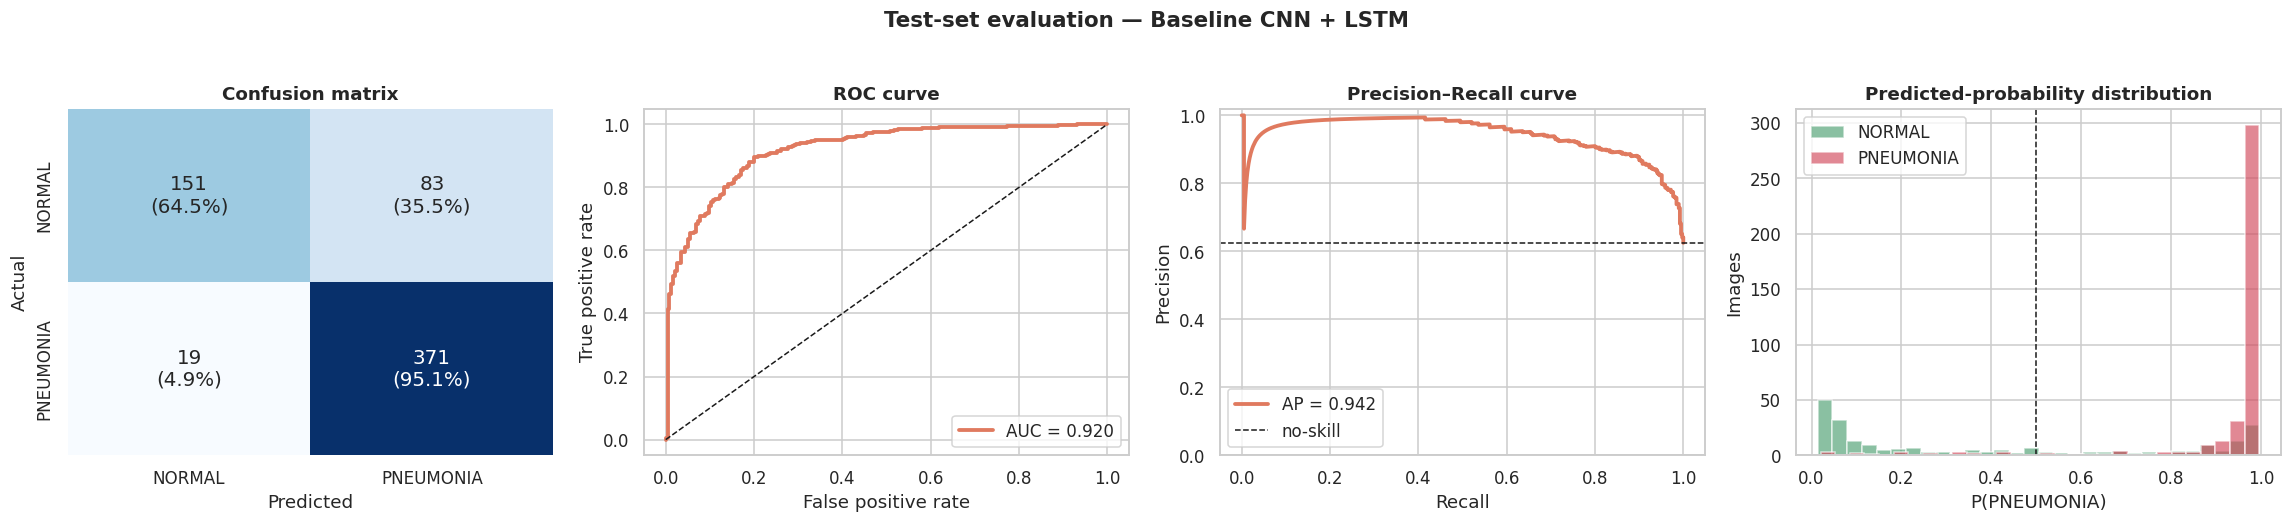

In [38]:
plot_history(hist_1, M1, color=MODEL_COLORS[M1])
evaluate_model(M1, model_1, hist_1, time_1);

In [39]:
run_ids[M1] = log_to_mlflow(M1, model_1,
    params={"backbone": "none (from scratch)", "head": "LSTM(128)", "lr_head": 1e-3,
            "lr_finetune": "n/a", "epochs_budget": EPOCHS_BASELINE},
    weights_path="saved_models/baseline_cnn_lstm.weights.h5")

2026/10/24 19:14:31 WARNING mlflow.keras.save: You are saving a Keras model without specifying model signature.


Logged 'Baseline CNN + LSTM' -> run_id = c6a0d31172f4472881aafd00adef92b3


## 8. Model 2 — Transfer Learning: DenseNet121 + LSTM



In [40]:
def build_densenet_lstm():
    base = keras.applications.DenseNet121(include_top=False, weights="imagenet", input_shape=INPUT_SHAPE)
    base.trainable = False

    inputs = keras.Input(INPUT_SHAPE, name="image")
    x = input_stem(inputs, imagenet_norm=True)
    x = base(x, training=False)                                  # BN layers stay in inference mode
    x = layers.Reshape((-1, 1024), name="to_sequence")(x)        # (49, 1024)
    x = layers.Dropout(0.3)(x)
    x = layers.LSTM(128, name="lstm")(x)
    x = layers.Dropout(0.4)(x)
    x = layers.Dense(64, activation="relu")(x)
    x = layers.Dropout(0.3)(x)
    outputs = layers.Dense(1, activation="sigmoid", name="pneumonia_prob")(x)
    return keras.Model(inputs, outputs, name="densenet121_lstm"), base

keras.backend.clear_session()
model_2, backbone_2 = build_densenet_lstm()
model_2.summary()

29084464/29084464 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step


Model: "densenet121_lstm"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ image (InputLayer)              │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling (Rescaling)           │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ augmentation (Sequential)       │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ imagenet_norm (Normalization)   │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ densenet121 (Functional)        │ (None, 7, 7, 1024)     │     7,037,504 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ to_sequence (Reshape)           │ (None, 49, 1024)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 49, 1024)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ (None, 128)            │       590,336 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pneumonia_prob (Dense)          │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 7,636,161 (29.13 MB)

 Trainable params: 598,657 (2.28 MB)

 Non-trainable params: 7,037,504 (26.85 MB)

In [41]:
t0 = time.time()

# ---- Phase 1: train the head only
compile_model(model_2, lr=1e-3)
h2a = model_2.fit(train_ds, validation_data=val_ds, epochs=EPOCHS_HEAD,
                  class_weight=class_weight_dict, callbacks=get_callbacks(patience=3), verbose=2)
ft_start_2 = len(h2a.history["loss"])

# ---- Phase 2: fine-tune last DenseNet block
unfreeze_for_finetuning(backbone_2)
compile_model(model_2, lr=1e-5)
h2b = model_2.fit(train_ds, validation_data=val_ds, epochs=EPOCHS_FINETUNE,
                  class_weight=class_weight_dict, callbacks=get_callbacks(patience=4), verbose=2)

time_2 = (time.time() - t0) / 60
hist_2 = merge_histories(h2a, h2b)
model_2.save_weights("saved_models/densenet121_lstm.weights.h5")
print(f"\nTotal training time: {time_2:.1f} min")

Epoch 1/8
139/139 - 50s - 360ms/step - accuracy: 0.8327 - auc: 0.9141 - loss: 0.3739 - precision: 0.9347 - recall: 0.8327 - val_accuracy: 0.9414 - val_auc: 0.9833 - val_loss: 0.1698 - val_precision: 0.9423 - val_recall: 0.9811 - learning_rate: 0.0010
Epoch 2/8
139/139 - 26s - 187ms/step - accuracy: 0.9224 - auc: 0.9720 - loss: 0.2082 - precision: 0.9713 - recall: 0.9227 - val_accuracy: 0.9363 - val_auc: 0.9878 - val_loss: 0.1517 - val_precision: 0.9872 - val_recall: 0.9262 - learning_rate: 0.0010
Epoch 3/8
139/139 - 26s - 188ms/step - accuracy: 0.9305 - auc: 0.9801 - loss: 0.1719 - precision: 0.9807 - recall: 0.9245 - val_accuracy: 0.9580 - val_auc: 0.9912 - val_loss: 0.1135 - val_precision: 0.9725 - val_recall: 0.9708 - learning_rate: 0.0010
Epoch 4/8
139/139 - 26s - 189ms/step - accuracy: 0.9316 - auc: 0.9786 - loss: 0.1788 - precision: 0.9792 - recall: 0.9276 - val_accuracy: 0.9592 - val_auc: 0.9930 - val_loss: 0.1206 - val_precision: 0.9928 - val_recall: 0.9520 - learning_rate: 0.0

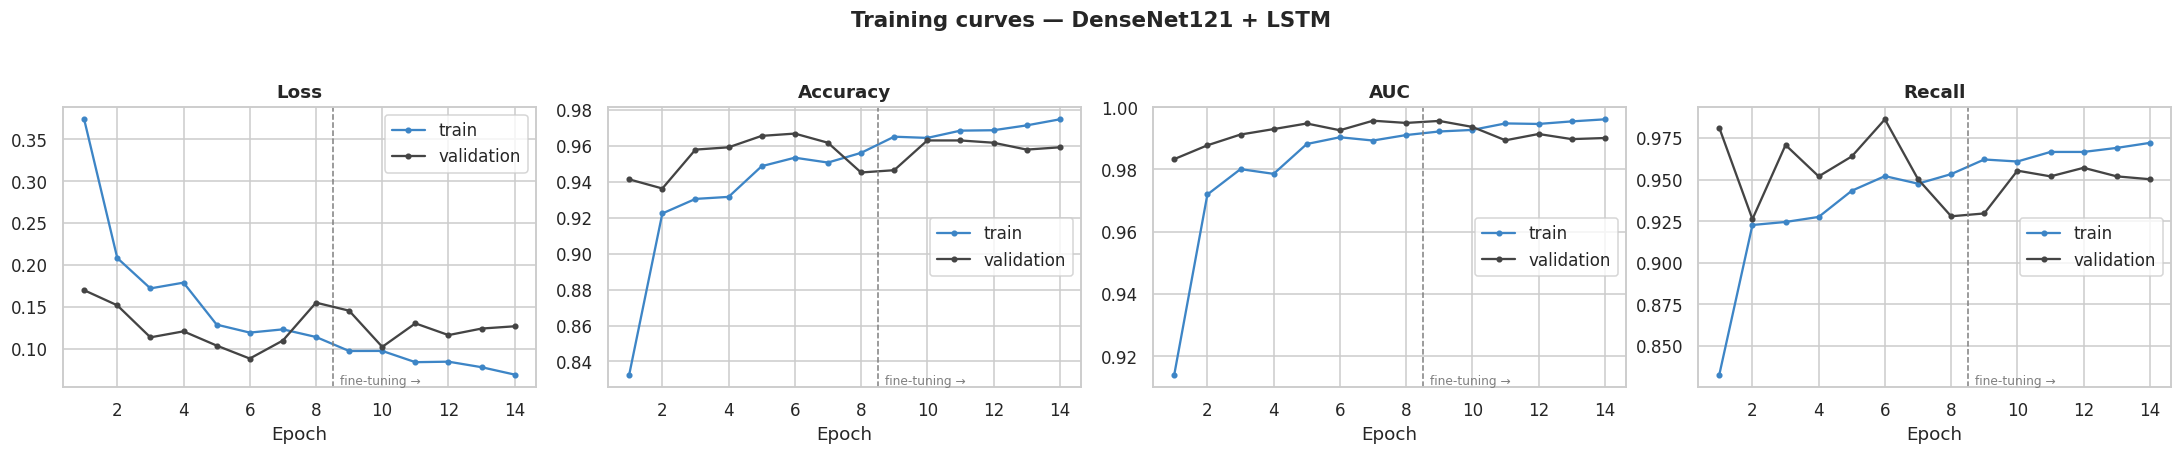

  TEST-SET EVALUATION — DenseNet121 + LSTM  (threshold = 0.5)
              precision    recall  f1-score   support

      NORMAL     0.9732    0.6197    0.7572       234
   PNEUMONIA     0.8126    0.9897    0.8925       390

    accuracy                         0.8510       624
   macro avg     0.8929    0.8047    0.8248       624
weighted avg     0.8728    0.8510    0.8417       624

ROC-AUC 0.9622 | PR-AUC 0.9751 | MCC 0.6920 | Specificity 0.6197 | FN (missed pneumonia) = 4


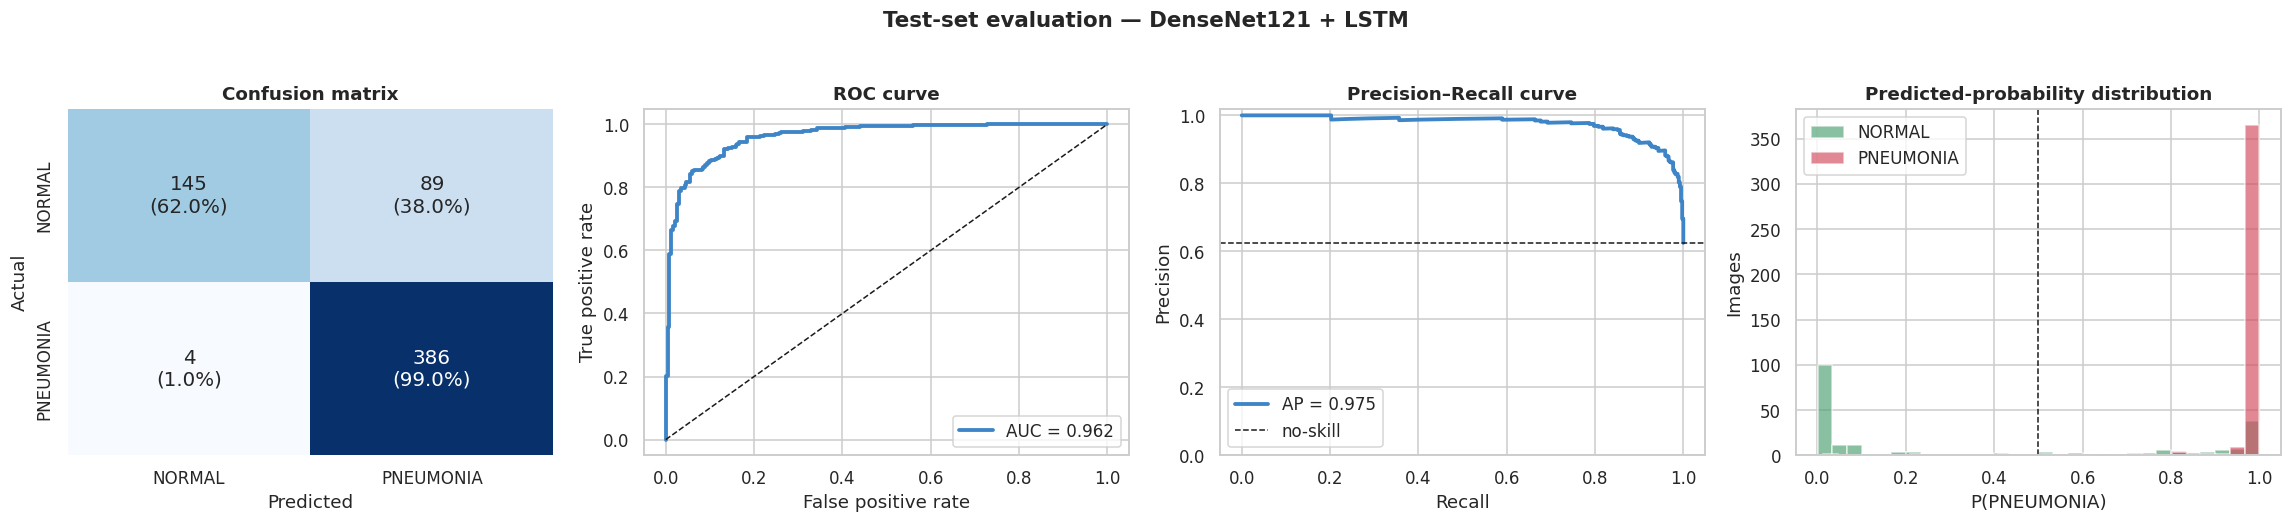

In [42]:
plot_history(hist_2, M2, finetune_start=ft_start_2, color=MODEL_COLORS[M2])
evaluate_model(M2, model_2, hist_2, time_2, finetune_start=ft_start_2);

In [43]:
run_ids[M2] = log_to_mlflow(M2, model_2,
    params={"backbone": "DenseNet121 (ImageNet)", "head": "LSTM(128)", "lr_head": 1e-3,
            "lr_finetune": 1e-5, "epochs_budget": EPOCHS_HEAD + EPOCHS_FINETUNE},
    weights_path="saved_models/densenet121_lstm.weights.h5")

2026/10/24 19:22:35 WARNING mlflow.keras.save: You are saving a Keras model without specifying model signature.


Logged 'DenseNet121 + LSTM' -> run_id = 477ceacc57894b359b3b7e0bcadad9ba


## 9. Model 3 — Advanced: DenseNet121 + Multi-Head Cross-Attention




In [44]:
@keras.utils.register_keras_serializable(package="xray")
class LearnedPositionalEmbedding(layers.Layer):
    """Adds a learnable position vector to every token of a (batch, tokens, dim) tensor."""
    def build(self, input_shape):
        self.pos = self.add_weight(name="pos", shape=(1, input_shape[1], input_shape[2]),
                                   initializer=keras.initializers.RandomNormal(stddev=0.02), trainable=True)
        super().build(input_shape)
    def call(self, x):
        return x + self.pos

def build_densenet_cross_attention(d_model=256, num_heads=8, dropout=0.1):
    base = keras.applications.DenseNet121(include_top=False, weights="imagenet", input_shape=INPUT_SHAPE)
    # Two views of the SAME backbone: mid-level (14×14) and final (7×7) features
    extractor = keras.Model(base.input,
                            [base.get_layer("conv4_block24_concat").output, base.output],
                            name="densenet_features")
    extractor.trainable = False

    inputs = keras.Input(INPUT_SHAPE, name="image")
    x = input_stem(inputs, imagenet_norm=True)
    mid, deep = extractor(x, training=False)

    # tokens
    kv = layers.Reshape((-1, mid.shape[-1]))(mid)               # (196, 1024)
    q  = layers.Reshape((-1, deep.shape[-1]))(deep)             # (49, 1024)
    kv = LearnedPositionalEmbedding(name="pos_kv")(layers.Dense(d_model, name="proj_kv")(kv))
    q  = LearnedPositionalEmbedding(name="pos_q")(layers.Dense(d_model, name="proj_q")(q))

    # multi-head cross-attention (+ residual)
    attn = layers.MultiHeadAttention(num_heads=num_heads, key_dim=d_model // num_heads,
                                     dropout=dropout, name="cross_attention")(query=q, value=kv, key=kv)
    x = layers.LayerNormalization(epsilon=1e-6)(q + layers.Dropout(dropout)(attn))

    # feed-forward (+ residual)
    ffn = layers.Dense(d_model * 2, activation="gelu")(x)
    ffn = layers.Dropout(dropout)(ffn)
    ffn = layers.Dense(d_model)(ffn)
    x = layers.LayerNormalization(epsilon=1e-6)(x + ffn)

    # classification head
    x = layers.GlobalAveragePooling1D()(x)
    x = layers.Dropout(0.4)(x)
    x = layers.Dense(64, activation="relu")(x)
    x = layers.Dropout(0.3)(x)
    outputs = layers.Dense(1, activation="sigmoid", name="pneumonia_prob")(x)
    return keras.Model(inputs, outputs, name="densenet121_cross_attention"), extractor

keras.backend.clear_session()
model_3, backbone_3 = build_densenet_cross_attention()
model_3.summary()

Model: "densenet121_cross_attention"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ image (InputLayer)  │ (None, 224, 224,  │          0 │ -                 │
│                     │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ rescaling           │ (None, 224, 224,  │          0 │ image[0][0]       │
│ (Rescaling)         │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ augmentation        │ (None, 224, 224,  │          0 │ rescaling[0][0]   │
│ (Sequential)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ imagenet_norm       │ (None, 224, 224,  │          0 │ augmentation[0][… │
│ (Normalization)     │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ densenet_features   │ [(None, 14, 14,   │  7,037,504 │ imagenet_norm[0]… │
│ (Functional)        │ 1024), (None, 7,  │            │                   │
│                     │ 7, 1024)]         │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ reshape_1 (Reshape) │ (None, 49, 1024)  │          0 │ densenet_feature… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ reshape (Reshape)   │ (None, 196, 1024) │          0 │ densenet_feature… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ proj_q (Dense)      │ (None, 49, 256)   │    262,400 │ reshape_1[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ proj_kv (Dense)     │ (None, 196, 256)  │    262,400 │ reshape[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ pos_q               │ (None, 49, 256)   │     12,544 │ proj_q[0][0]      │
│ (LearnedPositional… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ pos_kv              │ (None, 196, 256)  │     50,176 │ proj_kv[0][0]     │
│ (LearnedPositional… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ cross_attention     │ (None, 49, 256)   │    263,168 │ pos_kv[0][0],     │
│ (MultiHeadAttentio… │                   │            │ pos_q[0][0],      │
│                     │                   │            │ pos_kv[0][0]      │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_1 (Dropout) │ (None, 49, 256)   │          0 │ cross_attention[… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add (Add)           │ (None, 49, 256)   │          0 │ pos_q[0][0],      │
│                     │                   │            │ dropout_1[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ layer_normalization │ (None, 49, 256)   │        512 │ add[0][0]         │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense (Dense)       │ (None, 49, 512)   │    131,584 │ layer_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_2 (Dropout) │ (None, 49, 512)   │          0 │ dense[0][0]       │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_1 (Dense)     │ (None, 49, 256)   │    131,328 │ dropout_2[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_1 (Add)         │ (None, 49, 256)   │          0 │ layer_normalizat

 Total params: 8,168,641 (31.16 MB)

 Trainable params: 1,131,137 (4.31 MB)

 Non-trainable params: 7,037,504 (26.85 MB)

In [45]:
t0 = time.time()

# ---- Phase 1: train attention + head, backbone frozen
compile_model(model_3, lr=1e-3)
h3a = model_3.fit(train_ds, validation_data=val_ds, epochs=EPOCHS_HEAD,
                  class_weight=class_weight_dict, callbacks=get_callbacks(patience=3), verbose=2)
ft_start_3 = len(h3a.history["loss"])

# ---- Phase 2: fine-tune last DenseNet block
unfreeze_for_finetuning(backbone_3)
compile_model(model_3, lr=1e-5)
h3b = model_3.fit(train_ds, validation_data=val_ds, epochs=EPOCHS_FINETUNE,
                  class_weight=class_weight_dict, callbacks=get_callbacks(patience=4), verbose=2)

time_3 = (time.time() - t0) / 60
hist_3 = merge_histories(h3a, h3b)
model_3.save_weights("saved_models/densenet121_cross_attention.weights.h5")
print(f"\nTotal training time: {time_3:.1f} min")

Epoch 1/8
139/139 - 50s - 357ms/step - accuracy: 0.7958 - auc: 0.8978 - loss: 0.4014 - precision: 0.9253 - recall: 0.7885 - val_accuracy: 0.9490 - val_auc: 0.9878 - val_loss: 0.1458 - val_precision: 0.9517 - val_recall: 0.9811 - learning_rate: 0.0010
Epoch 2/8
139/139 - 27s - 197ms/step - accuracy: 0.9271 - auc: 0.9785 - loss: 0.1842 - precision: 0.9781 - recall: 0.9224 - val_accuracy: 0.9478 - val_auc: 0.9911 - val_loss: 0.1283 - val_precision: 0.9839 - val_recall: 0.9451 - learning_rate: 0.0010
Epoch 3/8
139/139 - 27s - 197ms/step - accuracy: 0.9454 - auc: 0.9882 - loss: 0.1343 - precision: 0.9832 - recall: 0.9424 - val_accuracy: 0.9185 - val_auc: 0.9933 - val_loss: 0.2013 - val_precision: 0.9981 - val_recall: 0.8919 - learning_rate: 0.0010
Epoch 4/8
139/139 - 28s - 201ms/step - accuracy: 0.9379 - auc: 0.9844 - loss: 0.1539 - precision: 0.9803 - recall: 0.9352 - val_accuracy: 0.9567 - val_auc: 0.9945 - val_loss: 0.1054 - val_precision: 0.9946 - val_recall: 0.9468 - learning_rate: 0.0

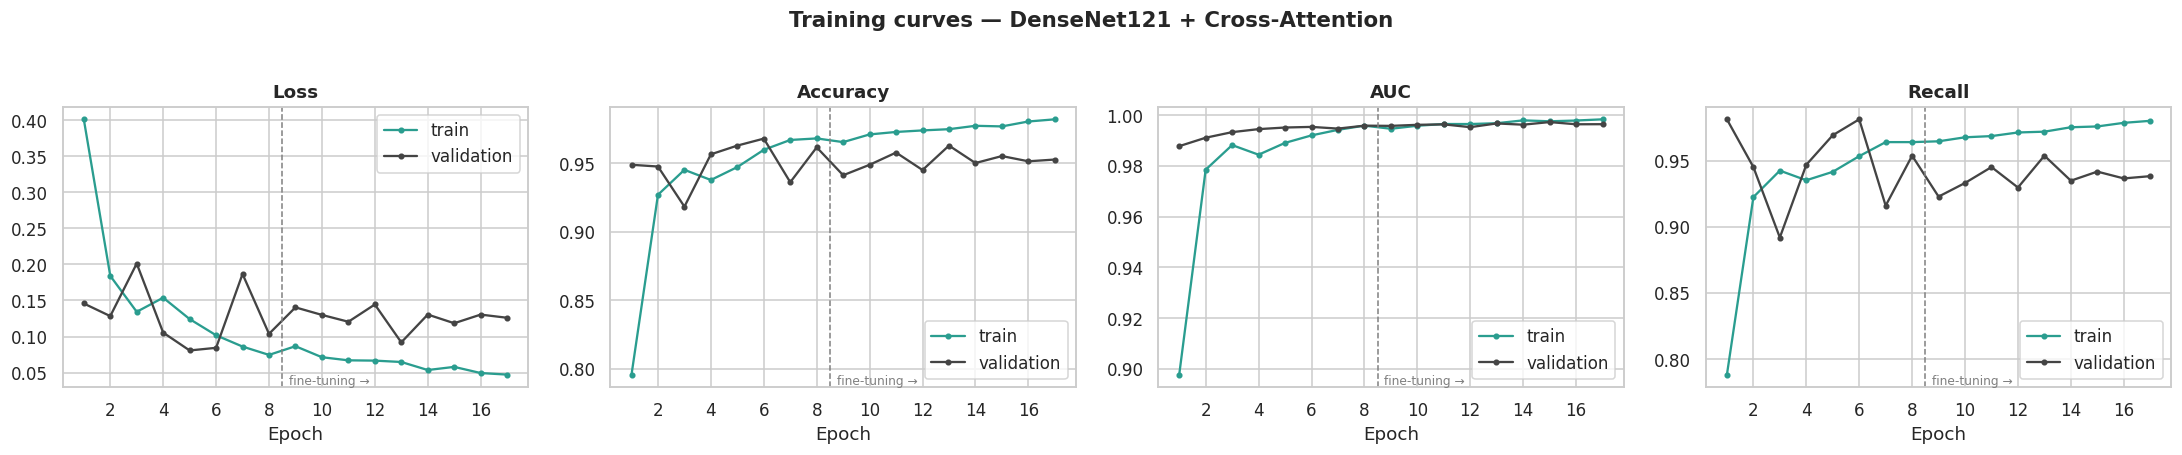

  TEST-SET EVALUATION — DenseNet121 + Cross-Attention  (threshold = 0.5)
              precision    recall  f1-score   support

      NORMAL     0.9818    0.6923    0.8120       234
   PNEUMONIA     0.8431    0.9923    0.9117       390

    accuracy                         0.8798       624
   macro avg     0.9125    0.8423    0.8618       624
weighted avg     0.8951    0.8798    0.8743       624

ROC-AUC 0.9658 | PR-AUC 0.9727 | MCC 0.7515 | Specificity 0.6923 | FN (missed pneumonia) = 3


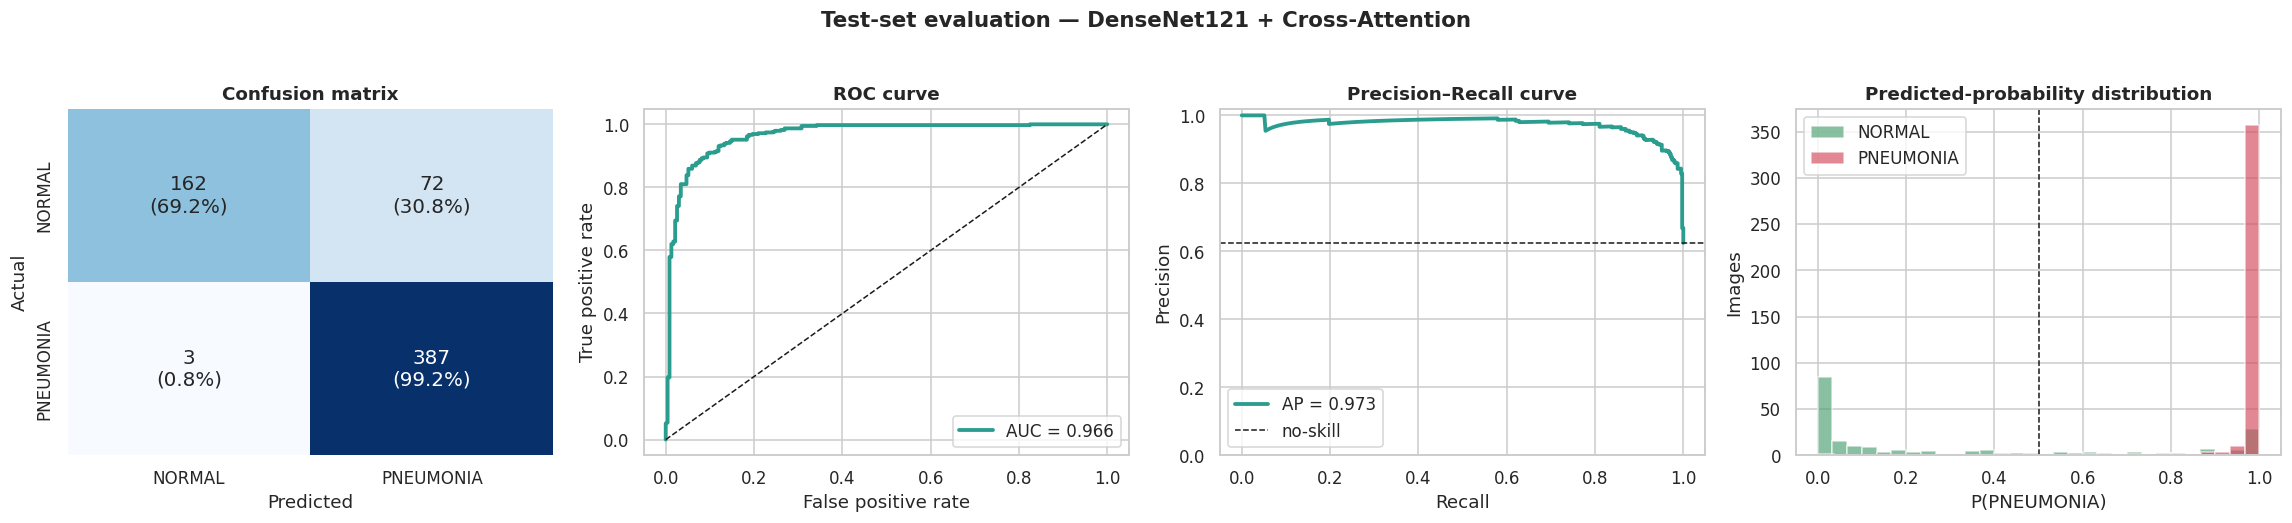

In [46]:
plot_history(hist_3, M3, finetune_start=ft_start_3, color=MODEL_COLORS[M3])
evaluate_model(M3, model_3, hist_3, time_3, finetune_start=ft_start_3);

In [47]:
run_ids[M3] = log_to_mlflow(M3, model_3,
    params={"backbone": "DenseNet121 (ImageNet)", "head": "Multi-Head Cross-Attention (8 heads, d=256)",
            "lr_head": 1e-3, "lr_finetune": 1e-5, "epochs_budget": EPOCHS_HEAD + EPOCHS_FINETUNE},
    weights_path="saved_models/densenet121_cross_attention.weights.h5")

2026/10/24 19:32:08 WARNING mlflow.keras.save: You are saving a Keras model without specifying model signature.
2026/10/24 19:32:21 WARNING mlflow.utils.environment: Encountered an unexpected error while inferring pip requirements (model URI: /tmp/tmpj7xkp6xh/model, flavor: keras). Fall back to return ['keras==3.13.2']. Set logging level to DEBUG to see the full traceback. 


Logged 'DenseNet121 + Cross-Attention' -> run_id = d626348ff8524104be641bcbfadc9034


## 10. Final comparison


In [48]:
order = [M1, M2, M3]
comparison = pd.DataFrame({n: results[n]["metrics"] for n in order}).T

perf_cols = ["Accuracy", "Precision", "Recall", "Specificity", "F1", "Macro F1", "Balanced Acc", "MCC", "ROC-AUC", "PR-AUC"]
cm_cols   = ["TP", "TN", "FP", "FN"]
cost_cols = ["Params (M)", "Train (min)", "Infer (ms/img)"]

print("🏆 Performance (best value per column highlighted)")
display(comparison[perf_cols].style.format("{:.4f}").highlight_max(axis=0, color="#b7e4c7"))

print("Confusion-matrix counts (FN = pneumonia cases the model MISSED — the most costly error)")
display(comparison[cm_cols].astype(int).style.highlight_min(subset=["FN", "FP"], axis=0, color="#b7e4c7"))

print("Computational cost")
display(comparison[cost_cols].style.format("{:.2f}").highlight_min(axis=0, color="#b7e4c7"))

comparison.to_csv("model_comparison.csv")

🏆 Performance (best value per column highlighted)


,Accuracy,Precision,Recall,Specificity,F1,Macro F1,Balanced Acc,MCC,ROC-AUC,PR-AUC
Baseline CNN + LSTM,0.8365,0.8172,0.9513,0.6453,0.8791,0.8133,0.7983,0.6487,0.9198,0.9424
DenseNet121 + LSTM,0.8510,0.8126,0.9897,0.6197,0.8925,0.8248,0.8047,0.6920,0.9622,0.9751
DenseNet121 + Cross-Attention,0.8798,0.8431,0.9923,0.6923,0.9117,0.8618,0.8423,0.7515,0.9658,0.9727


Confusion-matrix counts (FN = pneumonia cases the model MISSED — the most costly error)


,TP,TN,FP,FN
Baseline CNN + LSTM,371,151,83,19
DenseNet121 + LSTM,386,145,89,4
DenseNet121 + Cross-Attention,387,162,72,3


Computational cost


,Params (M),Train (min),Infer (ms/img)
Baseline CNN + LSTM,0.72,11.60,4.99
DenseNet121 + LSTM,7.64,7.11,17.53
DenseNet121 + Cross-Attention,8.17,8.95,16.09


### 10.2 Metric comparison

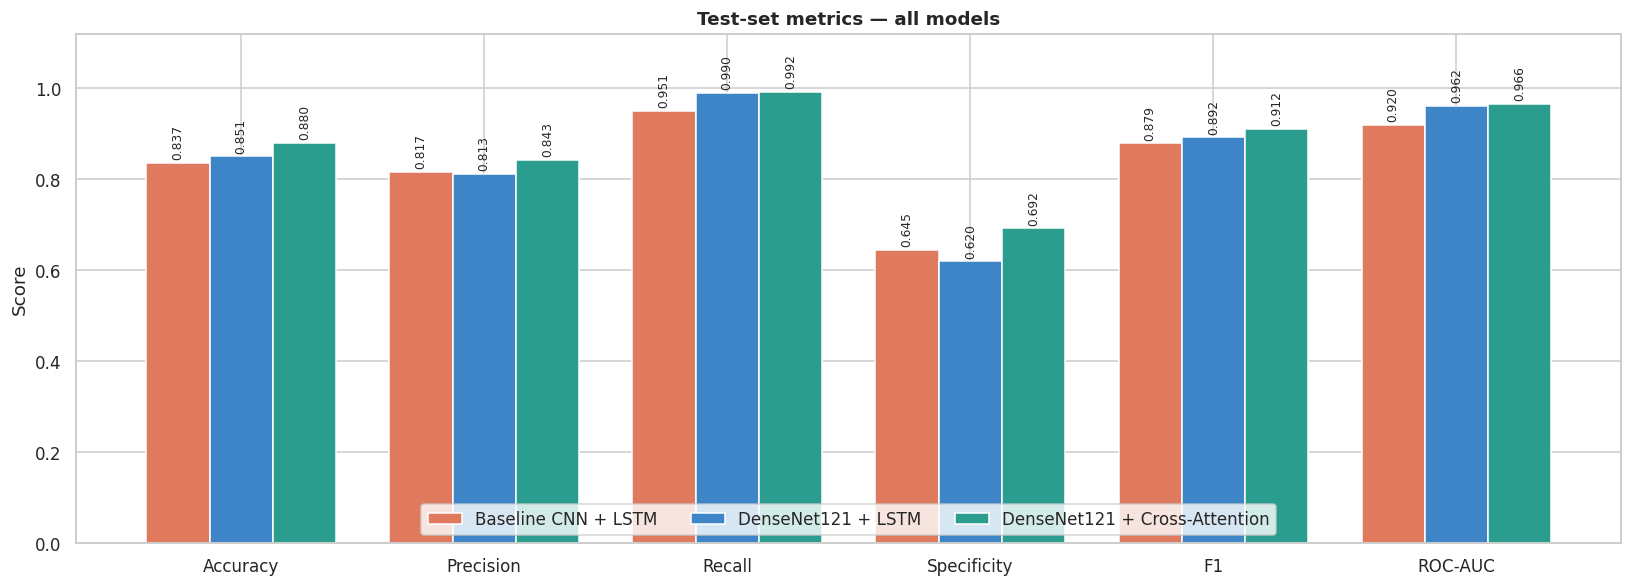

In [49]:
bar_metrics = ["Accuracy", "Precision", "Recall", "Specificity", "F1", "ROC-AUC"]
x = np.arange(len(bar_metrics)); w = 0.26

fig, ax = plt.subplots(figsize=(15, 5.5))
for i, n in enumerate(order):
    vals = comparison.loc[n, bar_metrics].values.astype(float)
    bars = ax.bar(x + (i - 1) * w, vals, w, label=n, color=MODEL_COLORS[n], edgecolor="white")
    ax.bar_label(bars, labels=[f"{v:.3f}" for v in vals], fontsize=8, padding=2, rotation=90)
ax.set_xticks(x); ax.set_xticklabels(bar_metrics, fontsize=11)
ax.set_ylim(0, 1.12); ax.set_ylabel("Score")
ax.set_title("Test-set metrics — all models"); ax.legend(loc="lower center", ncol=3, frameon=True)
plt.tight_layout(); plt.show()

### 10.3 ROC & Precision–Recall curves

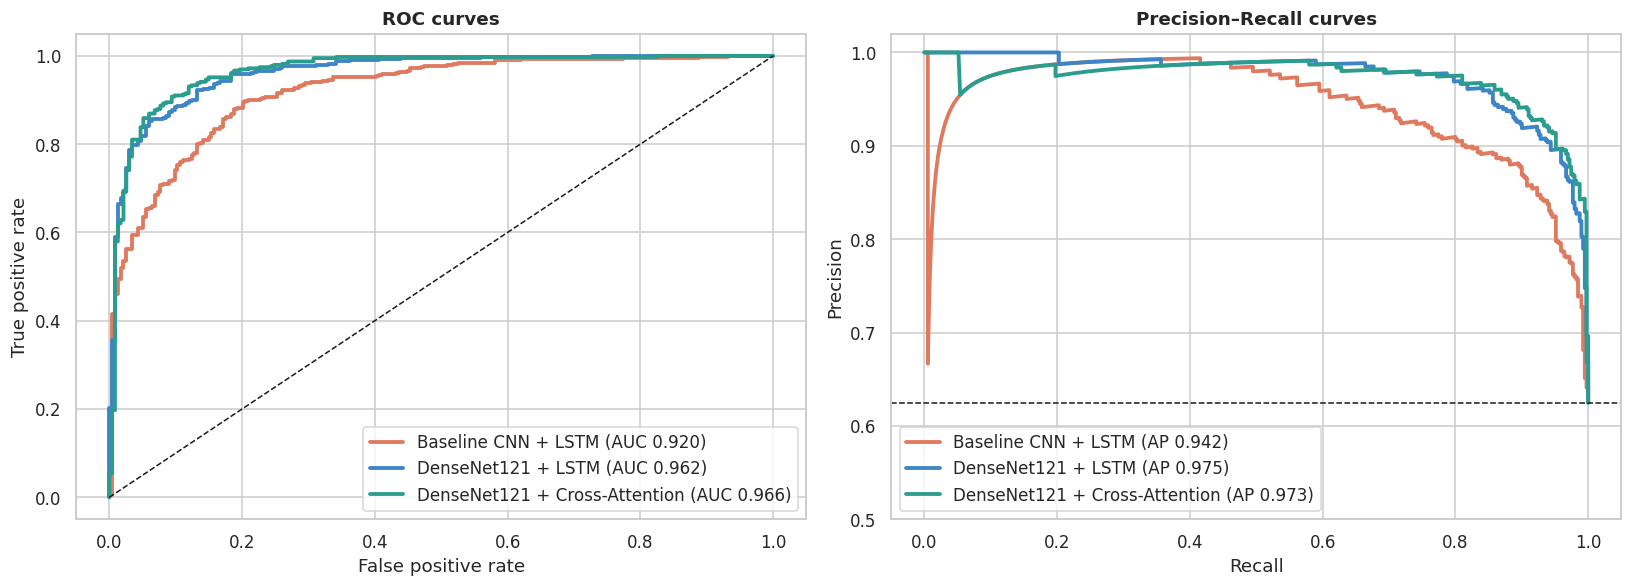

In [50]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))
for n in order:
    p = results[n]["y_prob"]
    fpr, tpr, _ = roc_curve(y_test, p)
    prec, rec, _ = precision_recall_curve(y_test, p)
    axes[0].plot(fpr, tpr, lw=2.5, color=MODEL_COLORS[n], label=f"{n} (AUC {roc_auc_score(y_test, p):.3f})")
    axes[1].plot(rec, prec, lw=2.5, color=MODEL_COLORS[n], label=f"{n} (AP {average_precision_score(y_test, p):.3f})")
axes[0].plot([0, 1], [0, 1], "k--", lw=1)
axes[0].set(title="ROC curves", xlabel="False positive rate", ylabel="True positive rate"); axes[0].legend(loc="lower right")
axes[1].axhline(y_test.mean(), color="k", ls="--", lw=1)
axes[1].set(title="Precision–Recall curves", xlabel="Recall", ylabel="Precision", ylim=(0.5, 1.02)); axes[1].legend(loc="lower left")
plt.tight_layout(); plt.show()

### 10.4 Confusion matrices side by side

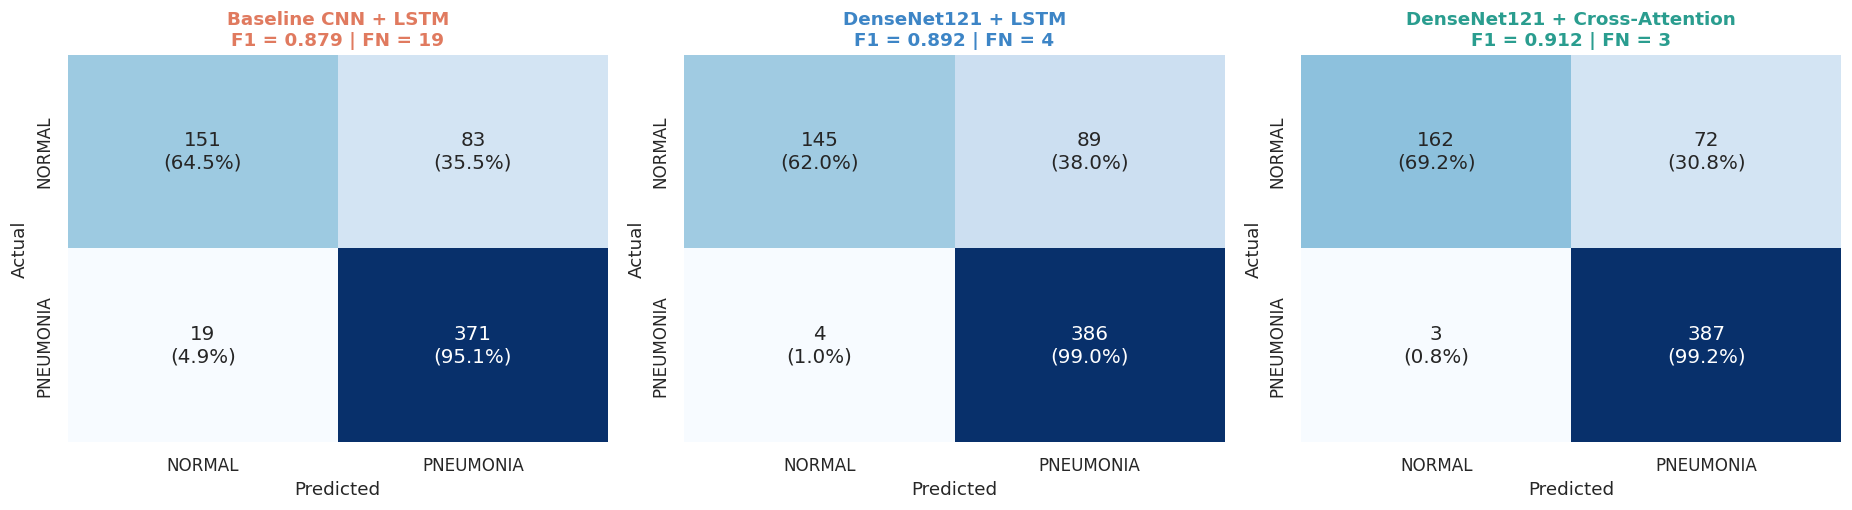

In [51]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.8))
for ax, n in zip(axes, order):
    cm = confusion_matrix(y_test, results[n]["y_pred"])
    annot = np.array([[f"{cm[i, j]}\n({cm[i, j] / cm[i].sum():.1%})" for j in range(2)] for i in range(2)])
    sns.heatmap(cm, annot=annot, fmt="", cmap="Blues", cbar=False, ax=ax,
                xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES, annot_kws={"size": 13})
    ax.set_title(f"{n}\nF1 = {comparison.loc[n, 'F1']:.3f} | FN = {int(comparison.loc[n, 'FN'])}", color=MODEL_COLORS[n])
    ax.set_xlabel("Predicted"); ax.set_ylabel("Actual")
plt.tight_layout(); plt.show()

### 10.5 Training behaviour & cost

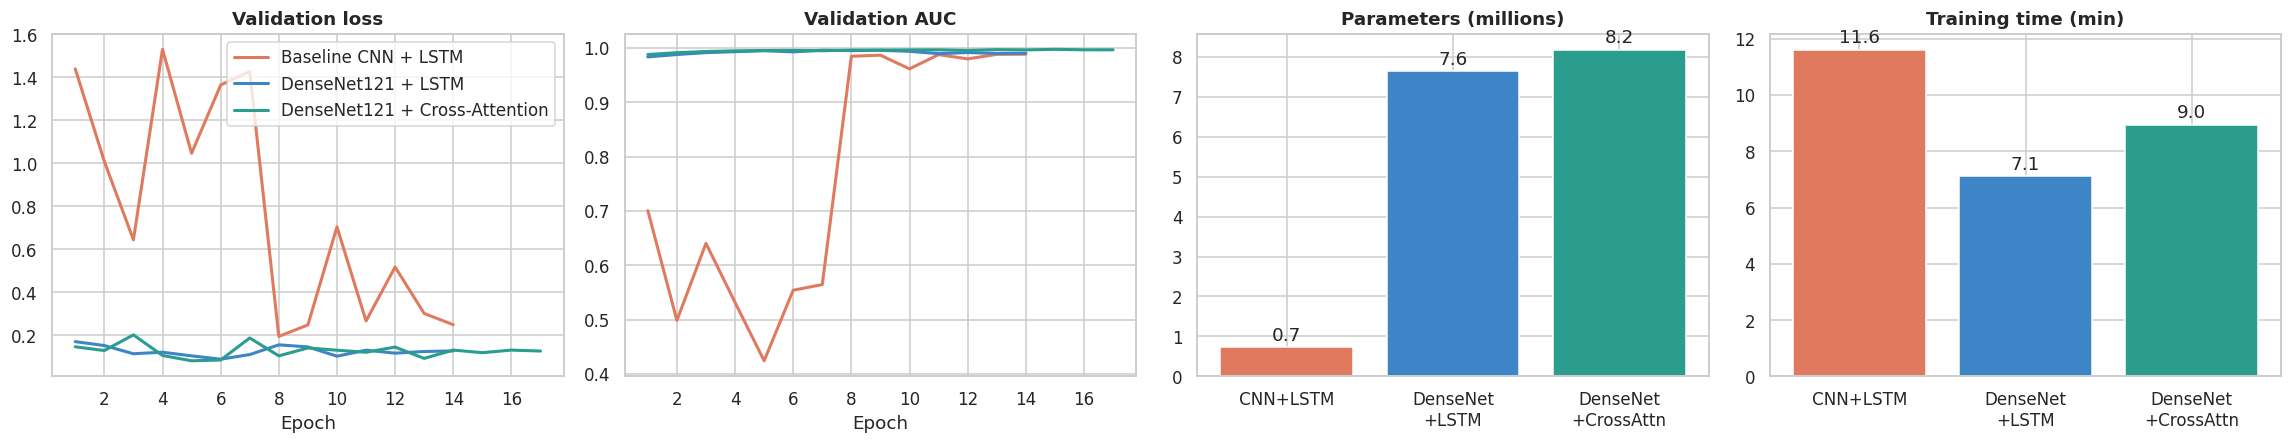

In [52]:
fig, axes = plt.subplots(1, 4, figsize=(21, 4.2))
for n in order:
    h = results[n]["history"]; ep = np.arange(1, len(h["loss"]) + 1)
    axes[0].plot(ep, h["val_loss"], lw=2, color=MODEL_COLORS[n], label=n)
    axes[1].plot(ep, h["val_auc"],  lw=2, color=MODEL_COLORS[n], label=n)
axes[0].set(title="Validation loss", xlabel="Epoch"); axes[1].set(title="Validation AUC", xlabel="Epoch")
axes[0].legend();

for ax, col, title in zip(axes[2:], ["Params (M)", "Train (min)"], ["Parameters (millions)", "Training time (min)"]):
    bars = ax.bar(range(3), comparison.loc[order, col].values, color=[MODEL_COLORS[n] for n in order])
    ax.bar_label(bars, fmt="%.1f", padding=2)
    ax.set_xticks(range(3)); ax.set_xticklabels(["CNN+LSTM", "DenseNet\n+LSTM", "DenseNet\n+CrossAttn"]); ax.set_title(title)
plt.tight_layout(); plt.show()

### 10.6 Ranking & verdict

In [53]:
rank_cols = ["Accuracy", "Precision", "Recall", "F1", "ROC-AUC", "PR-AUC", "MCC"]
ranks = comparison[rank_cols].astype(float).rank(ascending=False, method="min")
ranks["Mean rank"] = ranks.mean(axis=1)
display(ranks.sort_values("Mean rank").style.format("{:.1f}").background_gradient(cmap="RdYlGn_r", axis=None))

best_f1    = comparison["F1"].astype(float).idxmax()
best_rec   = comparison["Recall"].astype(float).idxmax()
best_auc   = comparison["ROC-AUC"].astype(float).idxmax()
best_rank  = ranks["Mean rank"].idxmin()

display(Markdown(f"""
## 🏁 Verdict
| Criterion | Winner |
|---|---|
| Best **F1** | **{best_f1}** ({comparison.loc[best_f1, 'F1']:.4f}) |
| Best **Recall** (fewest missed pneumonia cases) | **{best_rec}** ({comparison.loc[best_rec, 'Recall']:.4f}) — FN = {int(comparison.loc[best_rec, 'FN'])} |
| Best **ROC-AUC** (threshold-independent) | **{best_auc}** ({comparison.loc[best_auc, 'ROC-AUC']:.4f}) |
| Best **overall mean rank** | **{best_rank}** ({ranks.loc[best_rank, 'Mean rank']:.2f}) |

**Gain over baseline (F1):** {M2}: {comparison.loc[M2, 'F1'] - comparison.loc[M1, 'F1']:+.4f} · {M3}: {comparison.loc[M3, 'F1'] - comparison.loc[M1, 'F1']:+.4f}
"""))

,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC,MCC,Mean rank
DenseNet121 + Cross-Attention,1.0,1.0,1.0,1.0,1.0,2.0,1.0,1.1
DenseNet121 + LSTM,2.0,3.0,2.0,2.0,2.0,1.0,2.0,2.0
Baseline CNN + LSTM,3.0,2.0,3.0,3.0,3.0,3.0,3.0,2.9



## 🏁 Verdict
| Criterion | Winner |
|---|---|
| Best **F1** | **DenseNet121 + Cross-Attention** (0.9117) |
| Best **Recall** (fewest missed pneumonia cases) | **DenseNet121 + Cross-Attention** (0.9923) — FN = 3 |
| Best **ROC-AUC** (threshold-independent) | **DenseNet121 + Cross-Attention** (0.9658) |
| Best **overall mean rank** | **DenseNet121 + Cross-Attention** (1.14) |

**Gain over baseline (F1):** DenseNet121 + LSTM: +0.0133 · DenseNet121 + Cross-Attention: +0.0325


### 10.7 MLflow — compare runs & open the UI

In [54]:
# ---- A) Compare all runs in code (same table you see in the UI) ----
runs = mlflow.search_runs(experiment_names=["chest-xray-pneumonia"],
                          order_by=["metrics.test_F1 DESC"])
cols = ["tags.mlflow.runName", "metrics.test_F1", "metrics.test_Recall", "metrics.test_ROC-AUC",
        "metrics.test_FN", "metrics.test_Train_min", "params.backbone"]
display(runs[[c for c in cols if c in runs.columns]])

# ---- B) Register the best model (by F1) in the Model Registry ----
best_name = comparison["F1"].astype(float).idxmax()
try:
    mv = mlflow.register_model(f"runs:/{run_ids[best_name]}/model", "pneumonia-detector")
    print(f"Registered '{best_name}' as pneumonia-detector v{mv.version}")
except Exception as e:
    print("Registry step skipped:", e)

# ---- C) Open the UI ----
# Local machine : run in a terminal ->  mlflow ui --backend-store-uri sqlite:///mlflow.db   then open http://127.0.0.1:5000
# Colab/Kaggle  : uncomment below (needs a free ngrok token from ngrok.com)
# !pip install -q pyngrok
# import subprocess; from pyngrok import ngrok
# ngrok.set_auth_token("YOUR_NGROK_TOKEN")
# subprocess.Popen(["mlflow", "ui", "--backend-store-uri", "sqlite:///mlflow.db", "--port", "5000"])
# print("MLflow UI:", ngrok.connect(5000))

,tags.mlflow.runName,metrics.test_F1,metrics.test_Recall,metrics.test_ROC-AUC,metrics.test_FN,metrics.test_Train_min,params.backbone
0,DenseNet121 + Cross-Attention,0.911661,0.992308,0.965806,3.0,8.952341,DenseNet121 (ImageNet)
1,DenseNet121 + LSTM,0.892486,0.989744,0.962174,4.0,7.110704,DenseNet121 (ImageNet)
2,Baseline CNN + LSTM,0.879147,0.951282,0.919790,19.0,11.599997,none (from scratch)


Successfully registered model 'pneumonia-detector'.
2026/10/24 19:32:23 WARNING mlflow.tracking._model_registry.fluent: Run with id d626348ff8524104be641bcbfadc9034 has no artifacts at artifact path 'model', registering model based on models:/m-5de654d24dde407c9bad0718434ad825 instead


Registered 'DenseNet121 + Cross-Attention' as pneumonia-detector v1


Created version '1' of model 'pneumonia-detector'.


In [55]:
import shutil
shutil.make_archive("/kaggle/working/mlflow_artifacts", "zip", "/kaggle/working", "mlruns")

'/kaggle/working/mlflow_artifacts.zip'